# Lab: Online Machine Learning with River and CapyMOA

**Course:** M2 Data Science — Institut Polytechnique de Paris  
**Instructors:** Dr. Mariam BARRY, Dr. Maurras TOGBE  

This notebook implements and analyzes all steps (**Steps 1 to 10**) of the lab on Online Machine Learning using **River** (Part 1) and **CapyMOA** (Part 2), reusing and adapting the codebase in `src/`.

### Evaluation Protocol (Applied Across All Steps)
To ensure fair, reproducible, and leak-free comparisons across all models and libraries, we follow the evaluation protocol defined in `src/config.py`, `src/data.py`, and `src/evaluation.py`:
1. **Prequential (Test-then-Train) Evaluation:** Each incoming sample $(x_t, y_t)$ is first used to test the model (`predict_one`) and update evaluation metrics, and only then used to train the model (`learn_one`).
2. **Fixed Random Seeds & Identical Streams:** Every stochastic model and synthetic generator uses `SEED = 42`. Each stream is loaded once as a list of $(x_t, y_t)$ pairs (truncated to `N_MAX = 20,000` samples for large streams) so all models and both libraries see the exact same instances in the exact same order.
3. **No Data Leakage:** Feature engineering (`bikes_features`, `taxis_features`) is stateless (computed per instance). Feature and target scaling is performed strictly online (`StandardScaler` and `TargetStandardScaler` in River; causal running mean and variance over rows $0 \dots t-1$ in CapyMOA).
4. **Performance & Cost Metrics:** Alongside predictive performance, we report total runtime (`time_s`), per-instance latency (`latency_ms`), and final model memory usage (`memory_kb`).

---
## Part 1: River

### Step 1. Installation

**Objective:** Install River in a Python 3.11+ environment following the official guidelines (`pip install river`), verify the environment, and define the shared configuration from `src/config.py` and plotting helpers from `src/plotting.py`.

In [ ]:
# !pip install river

In [1]:
import importlib
import os
import platform
import sys
import types
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import river
from IPython.display import Image, display

# Make `src` importable both directly and via `Online_Machine_learning_Lab.src`
ROOT = Path.cwd()
for p in (str(ROOT), str(ROOT / "src")):
    if p not in sys.path:
        sys.path.insert(0, p)

import src

pkg = types.ModuleType("Online_Machine_learning_Lab")
pkg.__path__ = [str(ROOT)]
pkg.src = src
sys.modules["Online_Machine_learning_Lab"] = pkg
sys.modules["Online_Machine_learning_Lab.src"] = src

# Recall shared parameters and helpers directly from src/
from src.config import (
    CLASSIFICATION_DATASETS,
    DRIFT_POSITIONS,
    FIGURES,
    N_MAX,
    REGRESSION_DATASETS,
    ROLLING_WINDOW,
    SEED,
    SYNTHETIC_DATASETS,
    TABLES,
)
from src.plotting import plot_drifts, plot_rolling_losses, rolling

print(f"Python version : {platform.python_version()}")
print(f"River version  : {river.__version__}")
print(f"Configuration  : SEED={SEED}, N_MAX={N_MAX}, DRIFT_POSITIONS={DRIFT_POSITIONS}, ROLLING_WINDOW={ROLLING_WINDOW}")
print(f"Regression datasets     : {REGRESSION_DATASETS}")
print(f"Classification datasets : {CLASSIFICATION_DATASETS}")

Python version : 3.14.4
River version  : 0.26.1
Configuration  : SEED=42, N_MAX=20000, DRIFT_POSITIONS=(7000, 14000)

**Interpretation (Step 1):**  
River `0.26.1` is installed and running on Python `3.14.4`. All global parameters (`SEED = 42`, `N_MAX = 20,000`, and synthetic drift positions at `7,000` and `14,000`) and plotting utilities from `src/config.py` and `src/plotting.py` are initialized for consistent evaluation across all experiments.

---
### Step 2. Regression Methods and Datasets

**Objective:** Select 4 online regression methods of different types (tree-based, ensemble-based, linear with adaptive learning rate, and instance-based) and 4 datasets (3 real and 1 synthetic), reusing the implementations in `src/data.py` and `src/models.py`.

#### Methods Selected (`src/models.py`)
All regressors use `scaled_regressor(...)`, which chains online feature scaling (`preprocessing.StandardScaler()`) and online target scaling (`preprocessing.TargetStandardScaler`) learned incrementally without look-ahead:
1. **Tree-based (`HoeffdingTree`):** `tree.HoeffdingTreeRegressor(grace_period=200)` — incremental decision tree using the Hoeffding bound to evaluate splits.
2. **Ensemble-based (`ARF`):** `forest.ARFRegressor(n_models=10, seed=42)` — Adaptive Random Forest of 10 trees with online bagging and built-in drift detectors.
3. **Linear with adaptive learning rate (`LinearReg(Adam)`):** `linear_model.LinearRegression(optimizer=optim.Adam(lr=0.01))` — online linear regression updated with Adam.
4. **Other (`KNN`):** `neighbors.KNNRegressor(n_neighbors=5, engine=neighbors.LazySearch(window_size=500))` — 5-nearest-neighbor regression over a sliding window of the last 500 instances.

#### Datasets Selected (`src/data.py`)
1. **`Bikes` (Real, $N=20,000$):** Bike count in Toulouse bike-share stations using weather features, hour, weekday, and one-hot station indicator.
2. **`Taxis` (Real, $N=20,000$):** NYC taxi trip duration in seconds from pickup/dropoff coordinates, Euclidean distance, hour, weekday, and passenger count.
3. **`TrumpApproval` (Real, $N=1,001$):** Daily net approval rating from 6 polling indicators.
4. **`FriedmanDrift` (Synthetic, $N=20,000$):** 10-feature non-linear regression stream (`drift_type="gra"`, global recurring abrupt drift) with ground-truth abrupt drifts at instances **7,000** and **14,000**.

In [2]:
from src.data import bikes_features, load_regression, taxis_features, to_list
from src.models import KNN_WINDOW, regression_models, scaled_regressor

reg_summary = pd.DataFrame([
    {"Dataset": "Bikes", "Type": "Real", "Samples": N_MAX, "Description": "Toulouse bike-share availability (weather + time + station)"},
    {"Dataset": "Taxis", "Type": "Real", "Samples": N_MAX, "Description": "NYC taxi trip duration in seconds (coords + distance + time)"},
    {"Dataset": "TrumpApproval", "Type": "Real", "Samples": 1001, "Description": "Presidential approval rating (6 polling indicators)"},
    {"Dataset": "FriedmanDrift", "Type": "Synthetic", "Samples": N_MAX, "Description": f"Non-linear stream with abrupt drifts at {DRIFT_POSITIONS}"},
])
print(f"Selected regression models (KNN_WINDOW={KNN_WINDOW}):", list(regression_models().keys()))
display(reg_summary)

Selected regression models: ['HoeffdingTree', 'ARF', 'LinearReg(Adam)', 'KNN']

Dataset,Type,Samples,Description
Bikes,Real,20000,Toulouse bike-share availability (weather + time + station)
Taxis,Real,20000,NYC taxi trip duration in seconds (coords + distance + time)
TrumpApproval,Real,1001,Presidential approval rating (6 polling indicators)
FriedmanDrift,Synthetic,20000,"Non-linear stream with abrupt drifts at 7,000 and 14,000"


**Interpretation (Step 2):**  
The four selected regression methods represent four distinct online learning paradigms: a single incremental tree (`HoeffdingTree`), an adaptive tree ensemble (`ARF`), a linear model trained with adaptive gradient moments (`LinearReg(Adam)`), and a sliding-window non-parametric regressor (`KNN`). Evaluating them across three real-world streams of different sizes and noise levels (`Bikes`, `Taxis`, `TrumpApproval`) plus a synthetic stream with known abrupt drifts (`FriedmanDrift`) provides a comprehensive testbed for accuracy, speed, and adaptability.

---
### Step 3. Comparison of Regression Methods


dataset,model,n_samples,MAE,RMSE,R2,time_s,latency_ms,memory_kb
Bikes,HoeffdingTree,20000,6.0326,8.0729,0.0808,0.9633,0.0482,261.3389
Bikes,ARF,20000,4.0105,5.4771,0.5769,6.8686,0.3434,358.0527
Bikes,LinearReg(Adam),20000,4.9296,6.6358,0.3790,0.3007,0.0150,5.4023
Bikes,KNN,20000,6.2493,9.2933,-0.2181,2.8044,0.1402,295.9336
Taxis,HoeffdingTree,20000,533.1575,3905.5961,-0.0065,0.9471,0.0474,928.1133
Taxis,ARF,20000,398.8453,3876.9836,0.0082,18.4578,0.9229,46847.7861
Taxis,LinearReg(Adam),20000,683.6669,3961.7630,-0.0357,0.2861,0.0143,4.6172
Taxis,KNN,20000,583.2417,4219.3448,-0.1747,2.0351,0.1018,318.5469
TrumpApproval,HoeffdingTree,1001,0.3913,1.4562,0.2752,0.0340,0.0339,43.3271
TrumpApproval,ARF,1001,0.3726,1.4621,0.2694,0.4391,0.4387,1127.8877


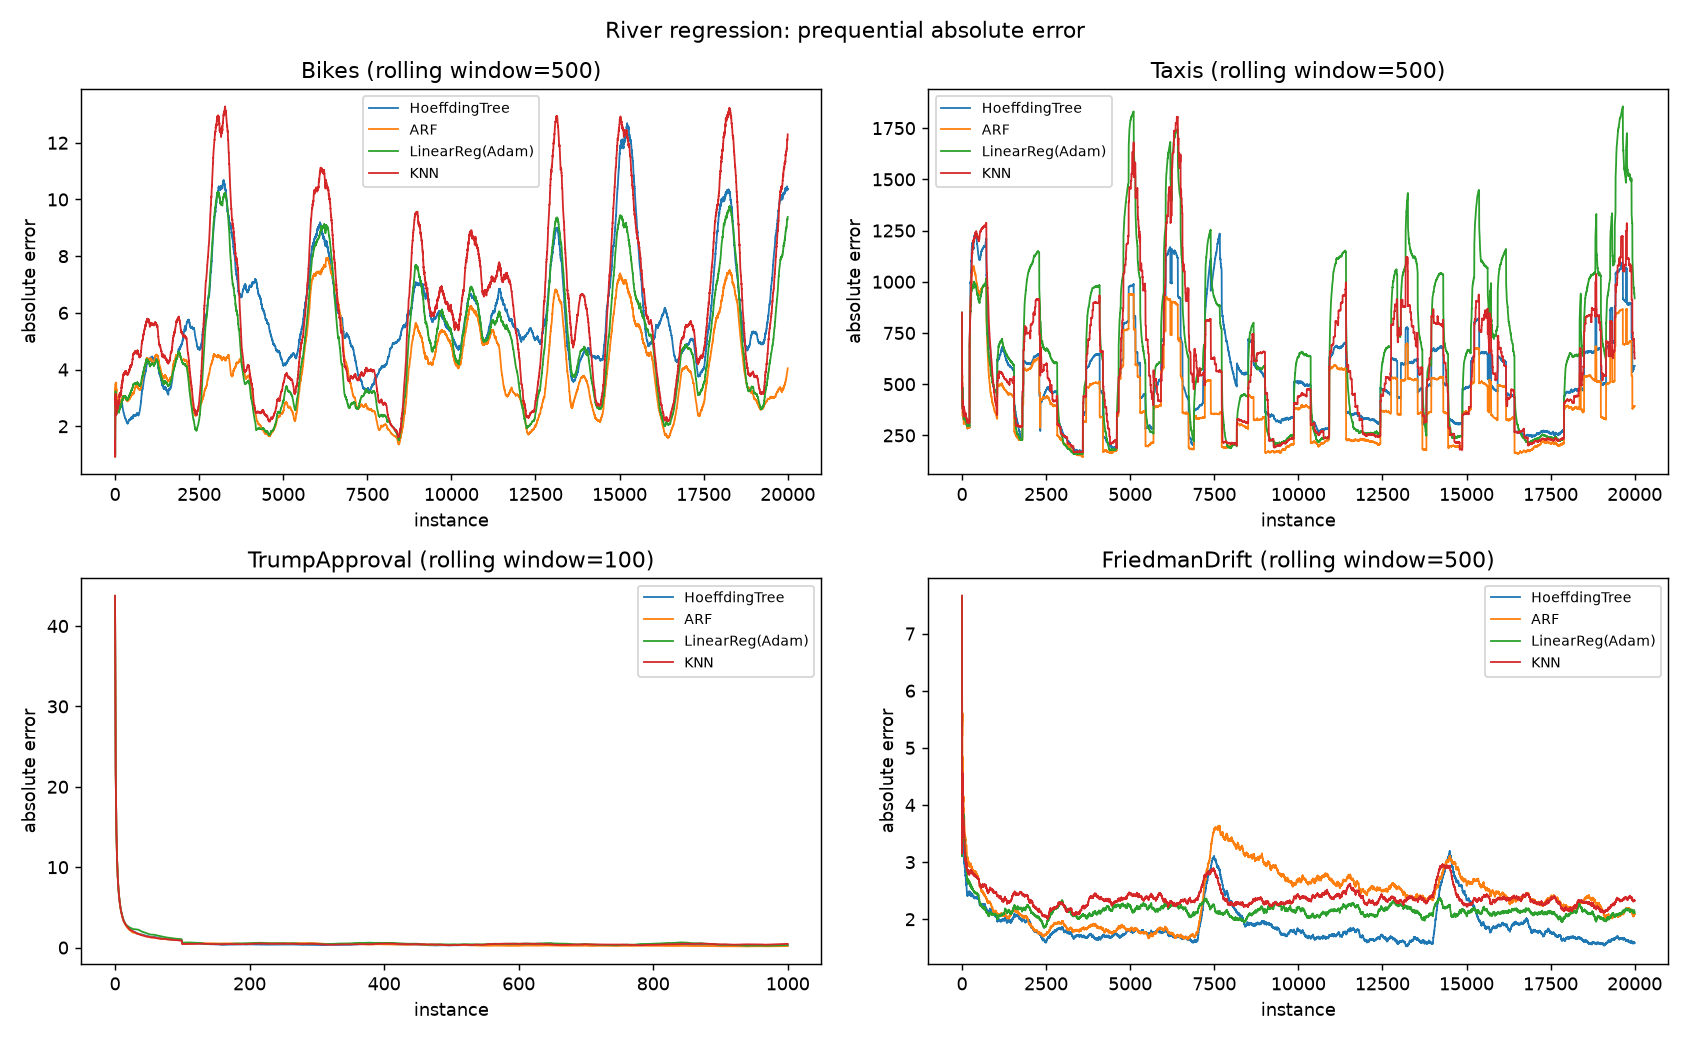

In [3]:
from src.evaluation import instance_loss, regression_metrics, run_prequential, update_metrics

river_comparison = importlib.import_module("01_river_comparison")
compare = river_comparison.compare

river_reg_df = compare("regression")
display(river_reg_df.round(4))
display(Image(filename=str(FIGURES / "river_regression_rolling.png")))

**Interpretation (Step 3):**  
`ARF` achieves the best accuracy on the complex real streams `Bikes` ($\text{MAE} = 4.01$, $R^2 = 0.5769$) and `Taxis` ($\text{MAE} = 398.85$, $R^2 = 0.0082$), while `HoeffdingTree` attains the best score on `TrumpApproval` ($R^2 = 0.2752$) and `FriedmanDrift` ($\text{MAE} = 1.8679$, $R^2 = 0.7573$). However, `ARF` has the highest latency ($0.34\text{--}1.12\text{ ms/instance}$) and memory usage (up to $65.0\text{ MB}$ on `FriedmanDrift`), whereas `LinearReg(Adam)` is the fastest model ($0.012\text{--}0.016\text{ ms/instance}$) and uses negligible memory ($\sim 4.4\text{--}5.4\text{ KB}$) while still achieving solid $R^2$ on `Bikes` ($0.3790$) and `FriedmanDrift` ($0.6911$). `KNN` requires moderate latency ($\sim 0.10\text{--}0.14\text{ ms/instance}$) and fixed window memory ($\sim 283\text{--}370\text{ KB}$), but performs poorly on noisy real streams like `Bikes` and `Taxis` ($R^2 < 0$).

---
### Step 4. Drift Detection (Regression)


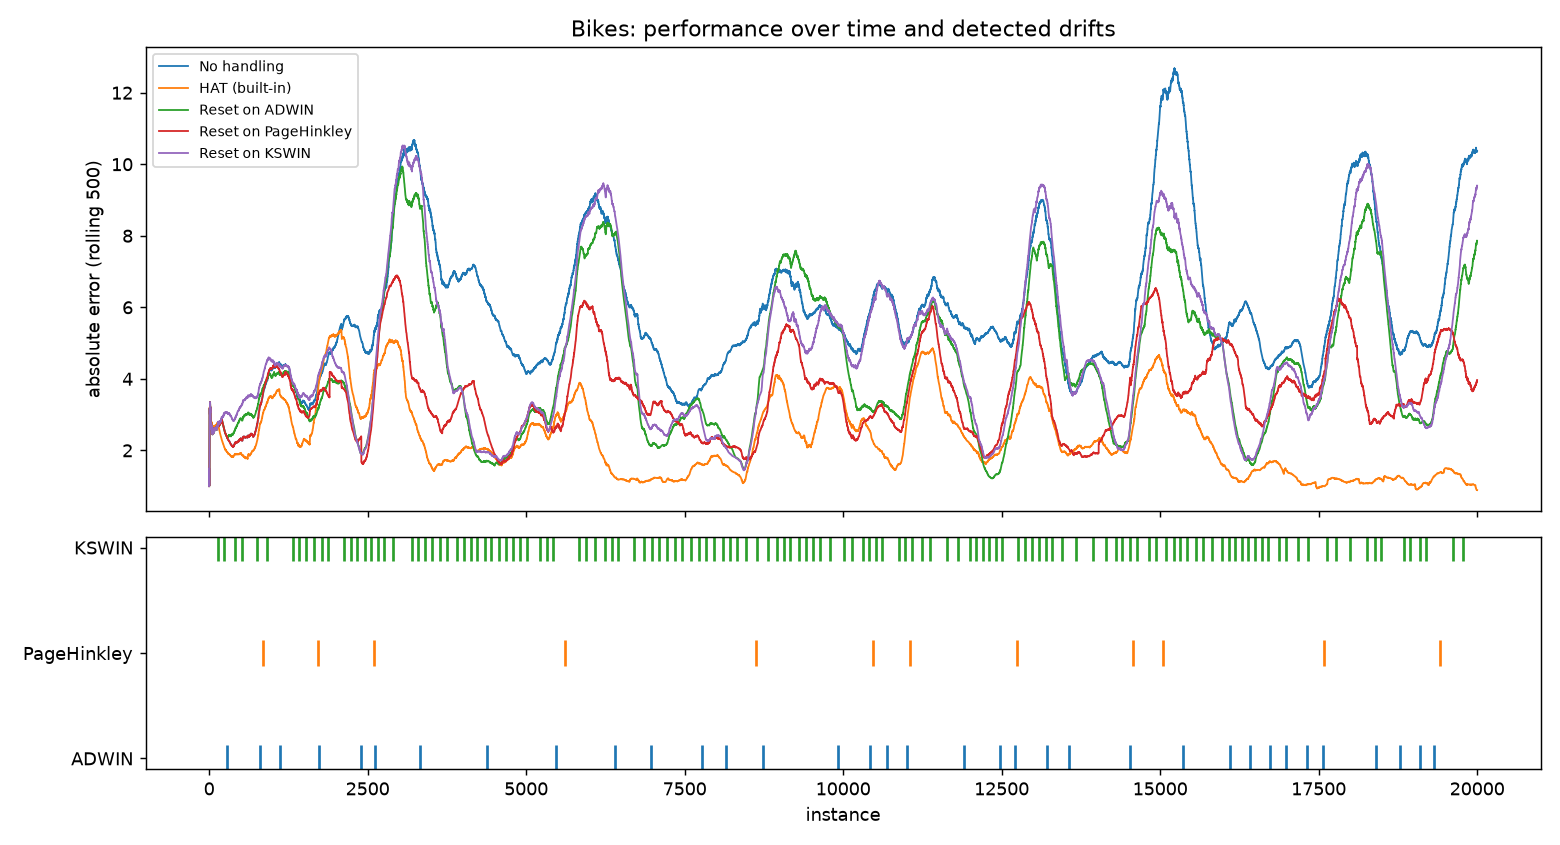

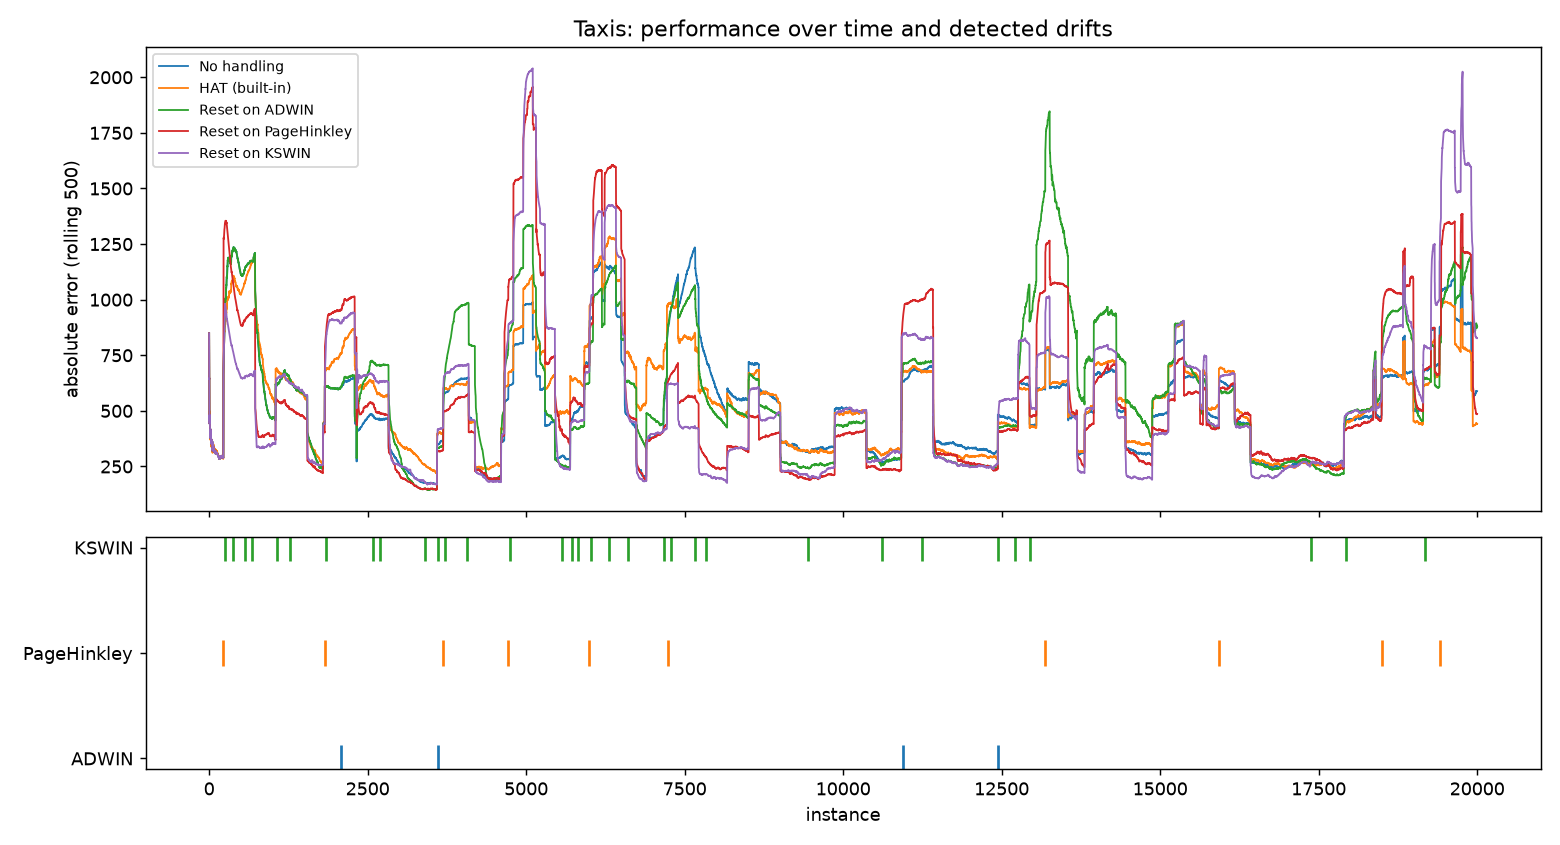

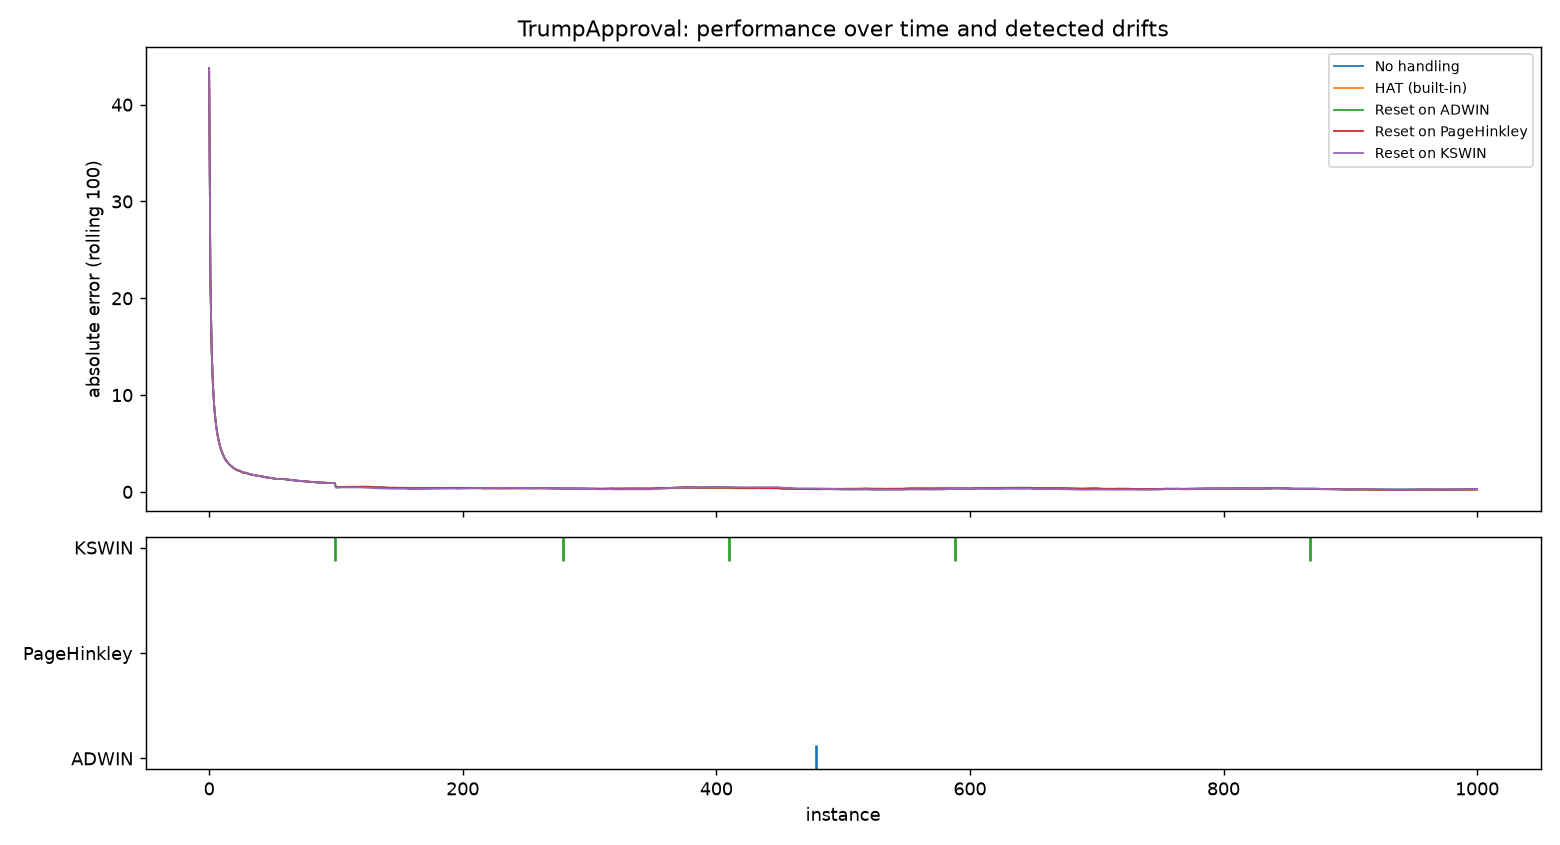

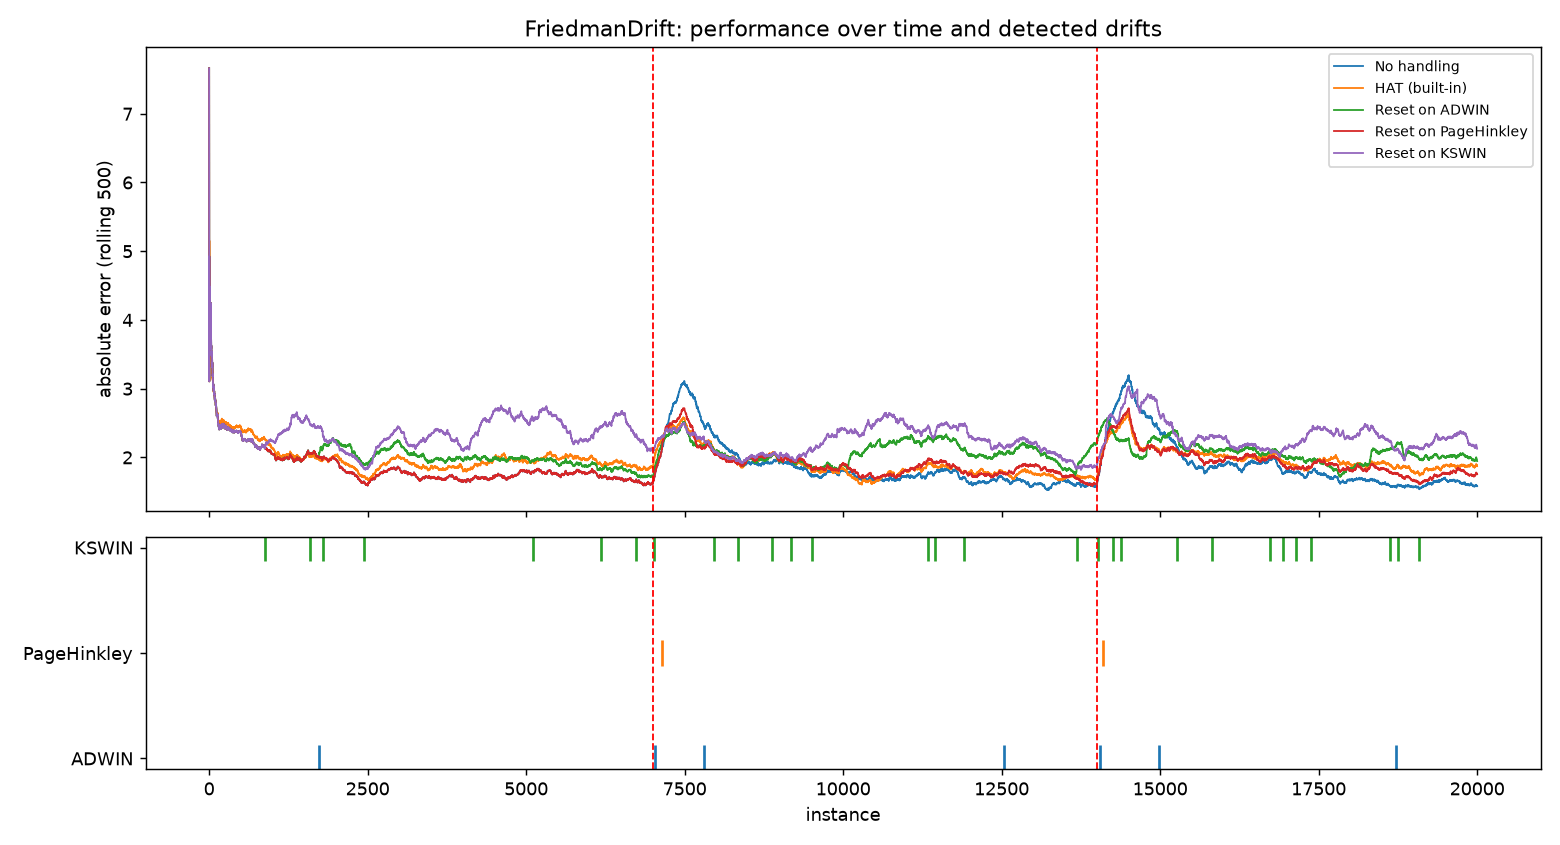

=== Regression Drift Detections ===

dataset,detector,n_detections,positions,delay@7000,delay@14000,false_alarms
Bikes,ADWIN,35,287 799 1119 1727 2399 2623 3327 4383 5471 6399 6975 7775 8159 8735 9919 ...,-,-,-
Bikes,PageHinkley,12,847 1721 2596 5618 8627 10473 11054 12745 14574 15048 17592 19418,-,-,-
Bikes,KSWIN,137,141 241 401 525 750 907 1319 1425 1530 1657 1773 1880 2133 2233 2333 ...,-,-,-
Taxis,ADWIN,4,2079 3615 10943 12447,-,-,-
Taxis,PageHinkley,10,225 1824 3692 4719 5999 7235 13188 15926 18494 19406,-,-,-
Taxis,KSWIN,33,250 377 567 683 1069 1271 1836 2580 2692 3411 3610 3725 4061 4745 5567 ...,-,-,-
TrumpApproval,ADWIN,1,479,-,-,-
TrumpApproval,PageHinkley,0,-,-,-,-
TrumpApproval,KSWIN,5,99 279 410 588 868,-,-,-
FriedmanDrift,ADWIN,7,1727 7039 7807 12543 14047 14975 18719,39.0,47.0,5.0


=== Regression Drift Handling Performance ===

dataset,strategy,n_resets,MAE,RMSE,R2,time_s,latency_ms
Bikes,No handling,0,6.0326,8.0729,0.0808,0.9977,0.0499
Bikes,HAT (built-in),0,2.3301,3.5175,0.8255,1.0226,0.0511
Bikes,Reset on ADWIN,54,4.5105,6.2477,0.4495,0.7953,0.0398
Bikes,Reset on PageHinkley,10,3.6272,5.8464,0.5179,0.8293,0.0415
Bikes,Reset on KSWIN,133,4.8818,6.6928,0.3682,2.5713,0.1286
Taxis,No handling,0,533.1575,3905.5961,-0.0065,0.9806,0.0490
Taxis,HAT (built-in),0,556.6970,3927.1787,-0.0177,1.2906,0.0645
Taxis,Reset on ADWIN,7,597.5350,3949.1767,-0.0291,1.0032,0.0502
Taxis,Reset on PageHinkley,9,555.4088,4471.7256,-0.3194,0.8924,0.0446
Taxis,Reset on KSWIN,69,563.4418,4105.6657,-0.1123,4.0880,0.2044


In [4]:
from src.evaluation import detection_delays, run_with_detector
from src.models import drift_adaptive_model, drift_base_model, regression_detectors

river_drift = importlib.import_module("02_river_drift")
drift_experiment = river_drift.drift_experiment

print("Regression drift detectors:", list(regression_detectors().keys()))
det_reg_df, perf_reg_df = drift_experiment("regression")

print("=== Regression Drift Detections ===")
display(det_reg_df.fillna("-"))
print("=== Regression Drift Handling Performance ===")
display(perf_reg_df.round(4))

for ds in REGRESSION_DATASETS:
    display(Image(filename=str(FIGURES / f"drift_regression_{ds}.png")))

**Interpretation (Step 4):**  
On `FriedmanDrift` (true drifts at 7,000 and 14,000), `KSWIN` detects the drifts with the shortest delays (16 and 27 instances) but triggers 27 false alarms; `ADWIN` detects both drifts rapidly (delays of 39 and 47 instances) with 5 false alarms; and `PageHinkley` detects both with zero false alarms at slightly longer delays (145 and 105 instances). On `Bikes`, drift handling dramatically improves performance over `No handling` ($R^2$ increases from $0.0808$ to $0.4495$ with `Reset on ADWIN` and $0.5179$ with `Reset on PageHinkley`), while `HAT (built-in)` reaches the highest accuracy ($R^2 = 0.8255$, $\text{MAE} = 2.33$) by selectively replacing only outdated tree branches. On `Taxis` and `FriedmanDrift`, frequent full resets (`Reset on KSWIN` with 69 and 40 resets) hurt $R^2$ and quadruple latency because the tree repeatedly loses learned structure after false alarms.

---
### Step 5. Classification: Methods, Datasets, Comparison, and Drift Detection

**Objective:** Repeat Steps 2 to 4 for online classification using 4 classification methods, 3 real datasets and 1 synthetic stream, evaluated with **Accuracy**, **Macro-F1**, and **Cohen's Kappa**, followed by drift detection with 4 binary detectors (`src/data.py`, `src/models.py`, `src/01_river_comparison.py`, and `src/02_river_drift.py`).

#### Classification Setup
* **4 Classification Methods (`src/models.py`):**
  1. **Tree-based (`HoeffdingTree`):** `tree.HoeffdingTreeClassifier(grace_period=200)`
  2. **Ensemble-based (`ARF`):** `forest.ARFClassifier(n_models=10, seed=42)`
  3. **Linear with adaptive learning rate (`LogReg(Adam)`):** `preprocessing.StandardScaler() | multiclass.OneVsRestClassifier(linear_model.LogisticRegression(optimizer=optim.Adam(lr=0.01)))`
  4. **Other (`GaussianNB`):** `naive_bayes.GaussianNB()`
* **4 Classification Datasets (`src/data.py`):**
  1. **`Elec2` (Real, binary, $N=20,000$):** Electricity price movement (up/down) with strong temporal/seasonal drift.
  2. **`Insects` (Real, 6 classes, $N=20,000$):** Optical sensor stream (`abrupt_balanced`, 33 numeric features) with abrupt concept drifts.
  3. **`Phishing` (Real, binary, $N=1,250$):** Website features for phishing detection.
  4. **`SEA_drift` (Synthetic, binary, $N=20,000$):** Nested `ConceptDriftStream` transitioning `SEA(variant=0) -> SEA(variant=1) -> SEA(variant=2)` (`width=50`) at instances **7,000** and **14,000**.
* **4 Classification Drift Detectors (`src/models.py`):** `ADWIN`, `DDM`, `EDDM`, and `HDDM_A` (`drift.binary.HDDMA()`).

dataset,model,n_samples,Accuracy,MacroF1,Kappa,time_s,latency_ms,memory_kb
Elec2,HoeffdingTree,20000,0.8308,0.8265,0.6534,0.4968,0.0248,420.7783
Elec2,ARF,20000,0.8967,0.8948,0.7895,10.6654,0.5333,4016.2197
Elec2,LogReg(Adam),20000,0.8468,0.8433,0.6867,0.4386,0.0219,4.6572
Elec2,GaussianNB,20000,0.7630,0.7529,0.5089,1.0262,0.0513,44.6680
Insects,HoeffdingTree,20000,0.5084,0.4874,0.4100,4.2580,0.2129,1149.7764
Insects,ARF,20000,0.7416,0.7371,0.6899,18.8361,0.9418,2457.6602
Insects,LogReg(Adam),20000,0.7472,0.7451,0.6967,2.4824,0.1241,10.1846
Insects,GaussianNB,20000,0.5099,0.4896,0.4118,3.1450,0.1573,541.1602
Phishing,HoeffdingTree,1250,0.8799,0.8776,0.7552,0.0374,0.0299,114.8320
Phishing,ARF,1250,0.9071,0.9060,0.8120,0.5513,0.4411,2406.0371


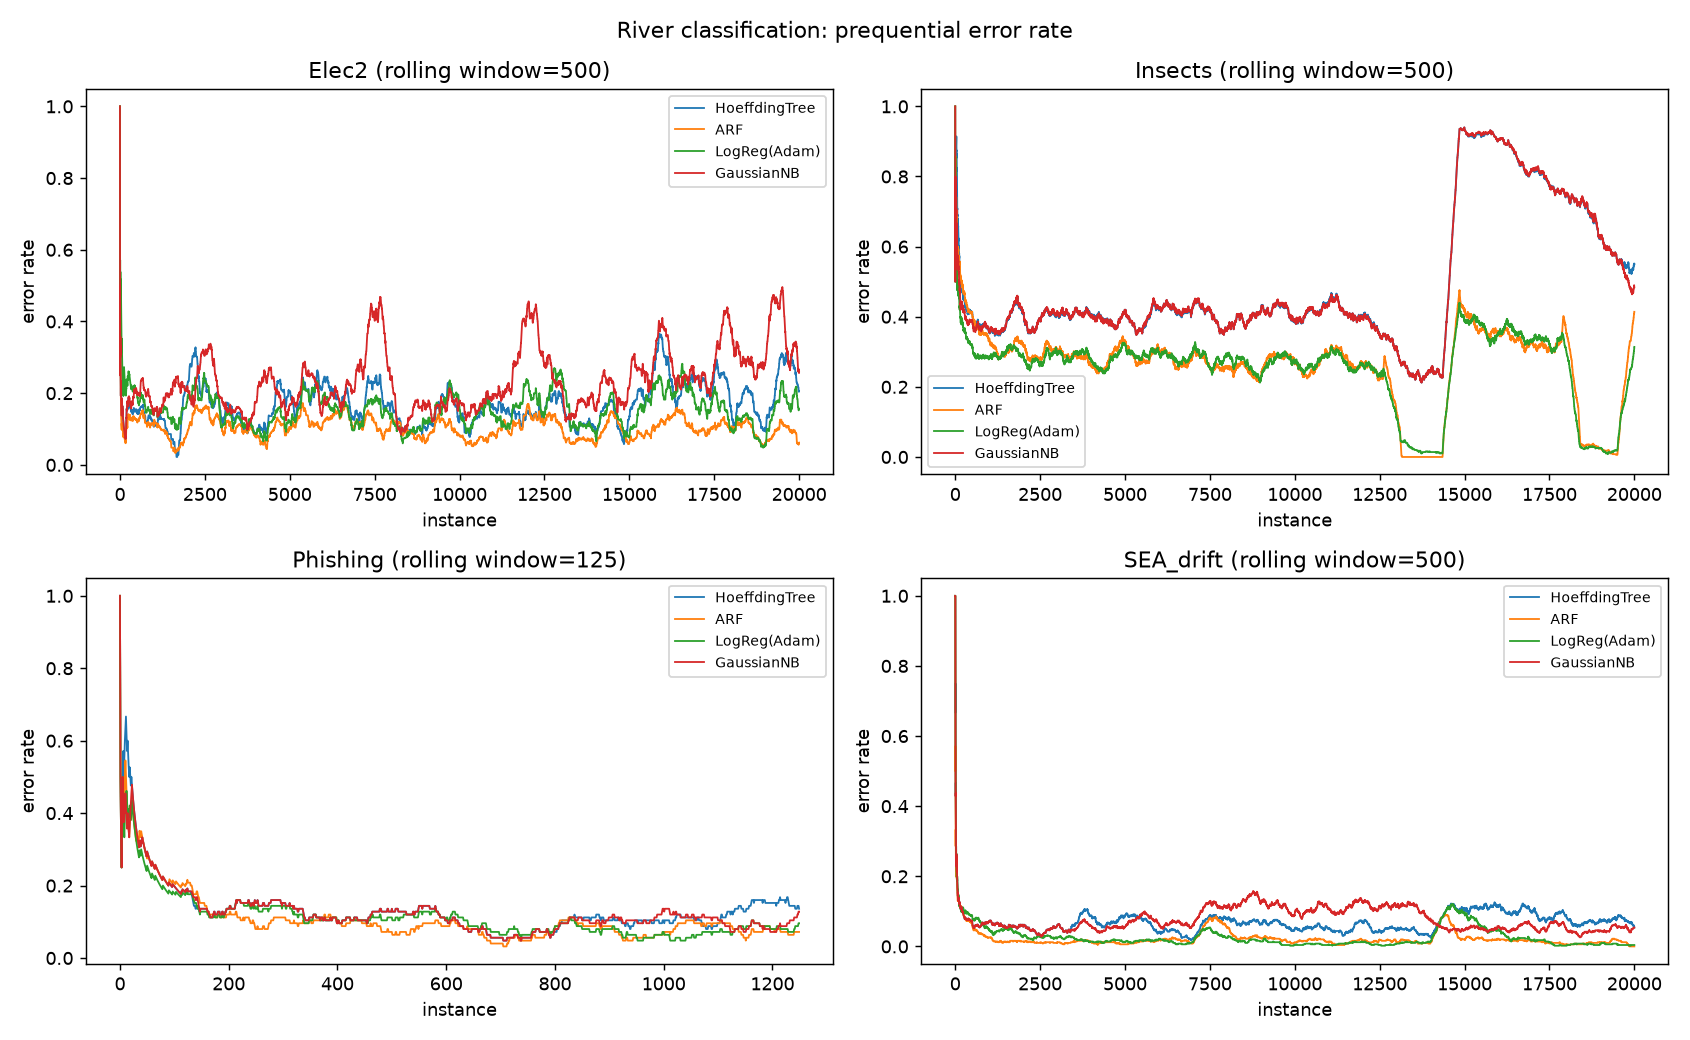

In [5]:
from src.data import SEA_DRIFT_WIDTH, load_classification, sea_concept_drift_stream
from src.evaluation import classification_metrics
from src.models import classification_models

print(f"Selected classification models (SEA_DRIFT_WIDTH={SEA_DRIFT_WIDTH}):", list(classification_models().keys()))
river_clf_df = compare("classification")
display(river_clf_df.round(4))
display(Image(filename=str(FIGURES / "river_classification_rolling.png")))

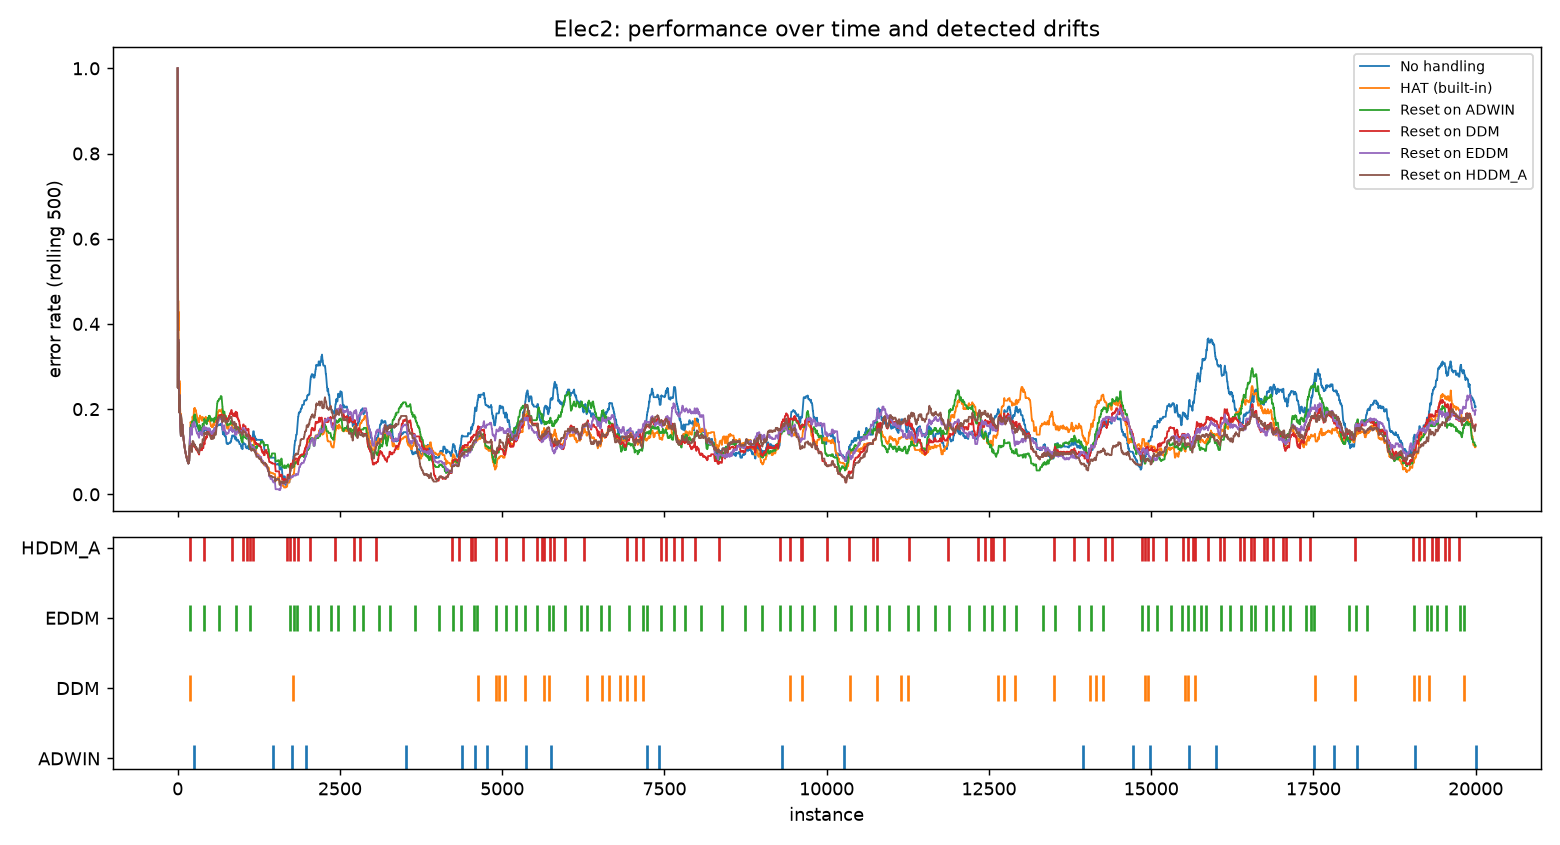

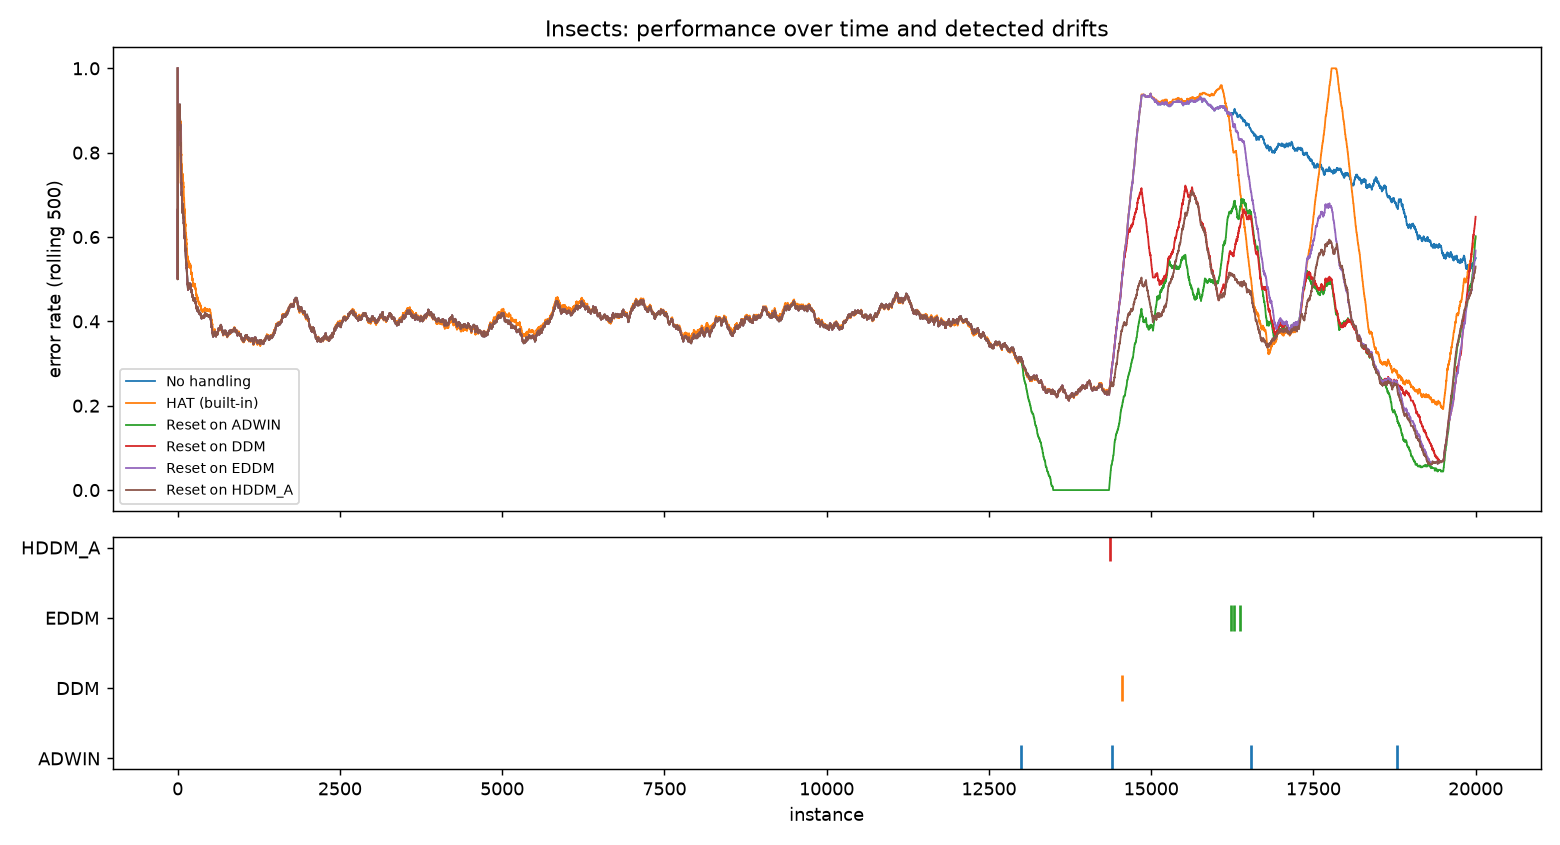

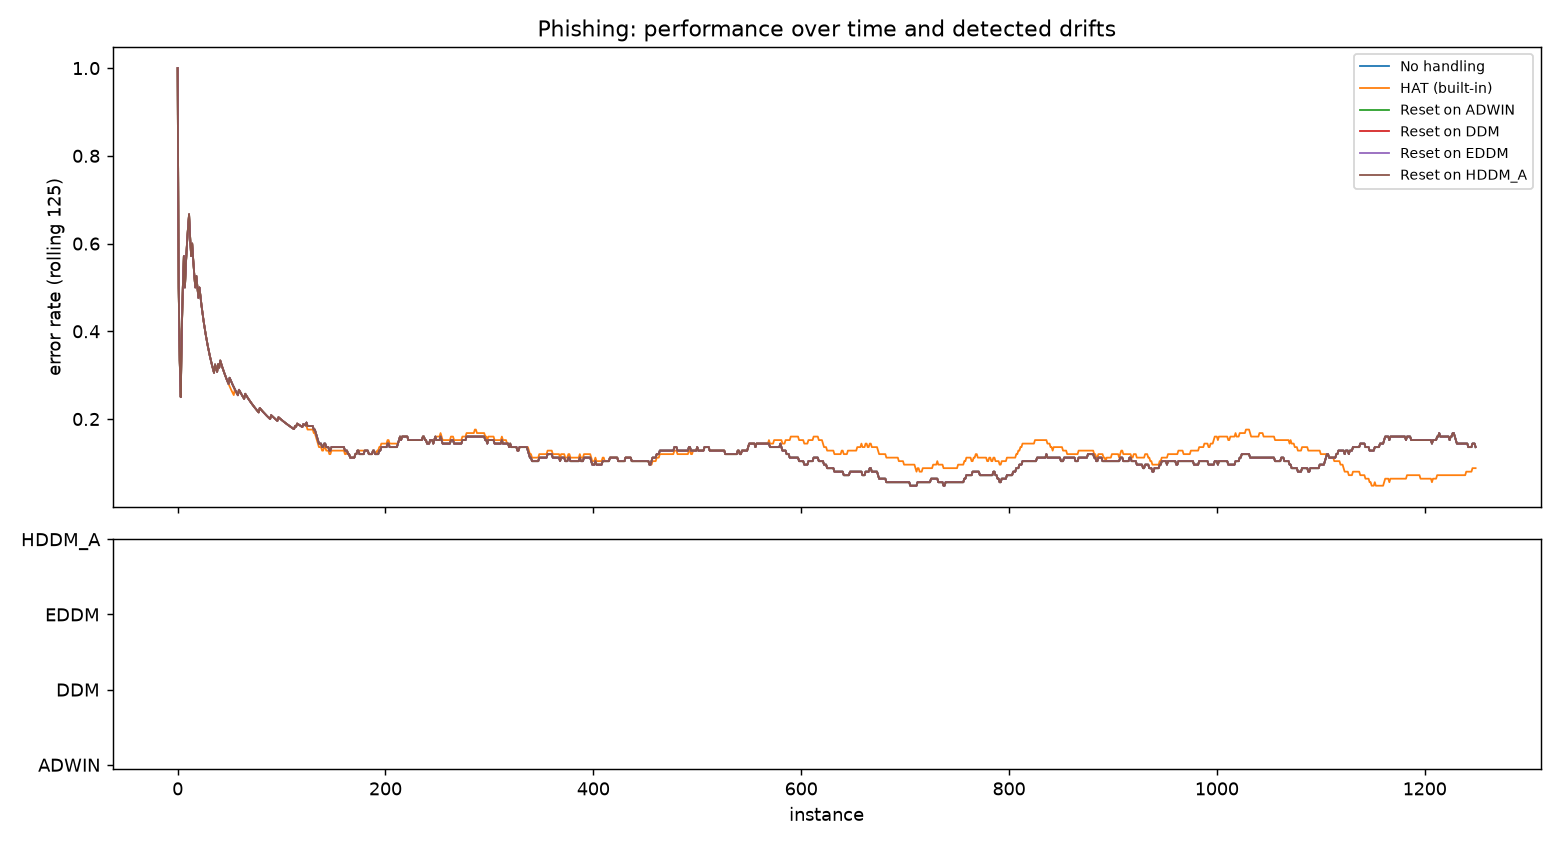

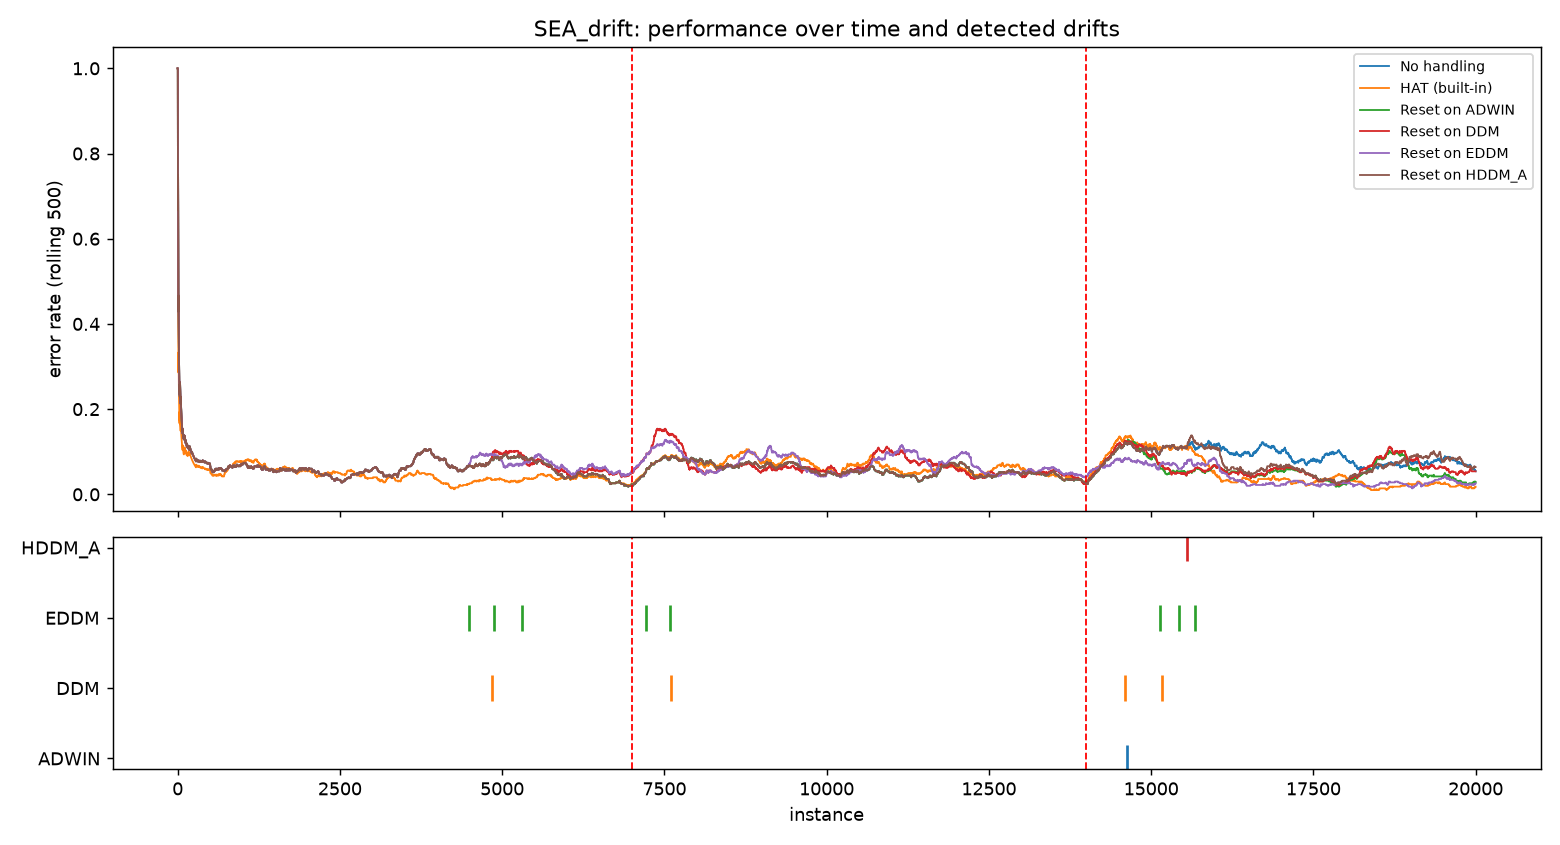

=== Classification Drift Detections ===

dataset,detector,n_detections,positions,delay@7000,delay@14000,false_alarms
Elec2,ADWIN,24,255 1471 1759 1983 3519 4383 4575 4767 5375 5759 7231 7423 9311 10271 13951 ...,-,-,-
Elec2,DDM,40,185 1781 4631 4902 4959 5041 5353 5648 5729 6312 6538 6651 6817 6923 7050 ...,-,-,-
Elec2,EDDM,98,197 406 635 894 1115 1725 1789 1843 2040 2168 2362 2470 2712 2849 3099 ...,-,-,-
Elec2,HDDM_A,93,184 408 837 1005 1068 1110 1164 1691 1730 1800 1849 2035 2427 2712 2813 ...,-,-,-
Insects,ADWIN,4,12991 14399 16543 18783,-,-,-
Insects,DDM,1,14554,-,-,-
Insects,EDDM,3,16223 16271 16364,-,-,-
Insects,HDDM_A,1,14361,-,-,-
Phishing,ADWIN,0,-,-,-,-
Phishing,DDM,0,-,-,-,-


=== Classification Drift Handling Performance ===

dataset,strategy,n_resets,Accuracy,MacroF1,Kappa,time_s,latency_ms
Elec2,No handling,0,0.8308,0.8265,0.6534,0.4987,0.0249
Elec2,HAT (built-in),0,0.8633,0.8609,0.7218,1.2503,0.0625
Elec2,Reset on ADWIN,20,0.8607,0.8579,0.7159,0.5207,0.0260
Elec2,Reset on DDM,68,0.8650,0.8630,0.7260,0.6915,0.0346
Elec2,Reset on EDDM,77,0.8576,0.8554,0.7107,0.5378,0.0269
Elec2,Reset on HDDM_A,60,0.8679,0.8657,0.7314,0.6746,0.0337
Insects,No handling,0,0.5084,0.4874,0.4100,4.0642,0.2032
Insects,HAT (built-in),0,0.5532,0.5345,0.4638,5.9543,0.2977
Insects,Reset on ADWIN,10,0.6285,0.6089,0.5542,3.7411,0.1871
Insects,Reset on DDM,9,0.5976,0.5794,0.5172,3.8975,0.1949


In [6]:
from src.models import classification_detectors

print("Classification drift detectors:", list(classification_detectors().keys()))
det_clf_df, perf_clf_df = drift_experiment("classification")

print("=== Classification Drift Detections ===")
display(det_clf_df.fillna("-"))
print("=== Classification Drift Handling Performance ===")
display(perf_clf_df.round(4))

for ds in CLASSIFICATION_DATASETS:
    display(Image(filename=str(FIGURES / f"drift_classification_{ds}.png")))

**Interpretation (Step 5):**  
In classification, `ARF` reaches the highest accuracy on `Elec2` ($89.67\%$, $\kappa = 0.7895$), `Phishing` ($90.71\%$), and `SEA_drift` ($97.98\%$), whereas `LogReg(Adam)` achieves the best accuracy on the 6-class `Insects` stream ($74.72\%$ vs. $74.16\%$ for `ARF` and $50.84\%$ for `HoeffdingTree`) while running $7.6\times$ faster ($0.12\text{ ms}$ vs. $0.94\text{ ms/instance}$) and using $240\times$ less memory ($10.2\text{ KB}$ vs. $2.46\text{ MB}$).  
In the drift experiments on `SEA_drift`, `DDM` and `EDDM` detect both true drifts at 7,000 and 14,000 (delays of 602/598 for `DDM` and 210/1143 for `EDDM`, with 2 and 6 false alarms), while `ADWIN` and `HDDM_A` miss the smaller first drift at 7,000 and detect only the larger drift at 14,000 (delays of 623 and 1,552) with zero false alarms. On non-stationary streams, drift adaptation significantly boosts the base `HoeffdingTree`: on `Insects`, `Reset on ADWIN` raises accuracy from $50.84\%$ to $62.85\%$ ($+12.01\%$), and on `Elec2` and `SEA_drift`, both detector resets ($86.79\%$ with `HDDM_A` and $94.18\%$ with `ADWIN`) and `HAT (built-in)` ($86.33\%$ and $94.67\%$) clearly outperform `No handling` ($83.08\%$ and $93.23\%$).

---
### Step 6. Report and Analysis of Part 1 (River)

#### 1. Accuracy vs. Computational Cost Trade-offs
| Model Family | River Models | Predictive Performance | Latency (`ms/instance`) | Memory (`KB`) | Main Trade-off |
| :--- | :--- | :--- | :---: | :---: | :--- |
| **Tree-based** | `HoeffdingTreeRegressor`, `HoeffdingTreeClassifier` | Strong on smooth/low-dim streams (`FriedmanDrift` $R^2=0.7573$, `SEA_drift` Acc $=93.23\%$); weak on drifting multi-class streams (`Insects` Acc $=50.84\%$) | Fast ($0.015\text{--}0.21\text{ ms}$) | Moderate ($43\text{--}3,013\text{ KB}$) | Low latency, but static splits become outdated after concept drift without a drift mechanism. |
| **Ensemble-based** | `ARFRegressor(10)`, `ARFClassifier(10)` | Best overall on 6/8 datasets (`Bikes` $R^2=0.5769$, `Elec2` Acc $=89.67\%$, `SEA_drift` Acc $=97.98\%$) | Slowest ($0.32\text{--}1.12\text{ ms}$) | Largest ($358\text{--}65,046\text{ KB}$) | Highest accuracy and built-in drift robustness, at $10\times\text{--}70\times$ higher runtime and memory cost. |
| **Linear + Adaptive LR** | `LinearReg(Adam)`, `LogReg(Adam)` | Best on `Insects` ($74.72\%$), close second on `SEA_drift` ($97.59\%$) and `Bikes` ($R^2=0.3790$) | Fastest ($0.012\text{--}0.12\text{ ms}$) | Minimal ($4.2\text{--}10.2\text{ KB}$) | Ideal for strict latency/memory budgets; Adam adapts weights continuously to drift, limited only by linearity. |
| **Other (KNN / NB)** | `KNNRegressor(k=5, w=500)`, `GaussianNB` | Competitive on short/simple streams (`Phishing` $88.47\%$, `TrumpApproval` $R^2=0.2370$); lags on complex streams | Low–Moderate ($0.04\text{--}0.16\text{ ms}$) | Low–Moderate ($18\text{--}541\text{ KB}$) | `GaussianNB` assumes feature independence and never forgets old statistics; `KNN` struggles with noise and high dimensions. |

#### 2. Drift Detectors and Adaptation Mechanisms
* **Detector Comparison:**
  * In regression (`FriedmanDrift`), `KSWIN` has the lowest detection delay (16–27 samples) but the highest false alarm count (27); `ADWIN` balances fast detection (39–47 samples) with few false alarms (5); `PageHinkley` yields zero false alarms with moderate delay (105–145 samples).
  * In classification (`SEA_drift`), `EDDM` and `DDM` are more sensitive to small error increases and catch both drifts at 7,000 and 14,000, whereas `ADWIN` and `HDDM_A` avoid false alarms completely but miss the subtle first drift.
* **Resetting vs. Built-in Subtree Replacement (`HAT`):**
  * Resetting a static `HoeffdingTree` when `ADWIN`, `PageHinkley`, or `HDDM_A` triggers significantly improves accuracy on non-stationary real streams (`Bikes`, `Elec2`, `Insects`).
  * However, full resets discard all previously learned knowledge. **`HAT (built-in)`** achieves better overall performance on `Bikes` ($R^2=0.8255$), `FriedmanDrift` ($R^2=0.7438$ vs. $0.7130$ for `ADWIN` reset), and `SEA_drift` ($94.67\%$) by growing alternate branches in the background and replacing only degraded subtrees.

**Interpretation (Step 6 Summary):**  
Part 1 demonstrates that no single online learner dominates all metrics: `ARF` maximizes accuracy when compute resources are plentiful, while `LinearReg(Adam)` / `LogReg(Adam)` provides the best throughput and memory efficiency. For tree-based models on evolving streams, combining a learner with `ADWIN` or using `HoeffdingAdaptiveTree` (`HAT`) is essential to recover from concept drift without excessive false alarms.

---
## Part 2: CapyMOA

### Step 7. Installation

**Objective:** Install CapyMOA (`pip install capymoa`) following the official documentation and verify that the Java runtime (OpenJDK 17+ via JPype) is active.

In [7]:
# Uncomment to install CapyMOA if needed:
# !pip install capymoa

jdk_path = "/opt/homebrew/opt/openjdk@17/libexec/openjdk.jdk/Contents/Home"
if "JAVA_HOME" not in os.environ and os.path.exists(jdk_path):
    os.environ["JAVA_HOME"] = jdk_path

import capymoa
import jpype

print(f"CapyMOA version : {capymoa.__version__}")
print(f"JVM started     : {jpype.isJVMStarted()}")
print(f"JVM version     : {jpype.getJVMVersion()}")

CapyMOA version : 0.15.1
JVM started     : True
JVM version     : (17, 0, 18)

**Interpretation (Step 7):**  
CapyMOA `0.15.1` is installed and running over OpenJDK `17.0.18` via JPype. This Java bridge enables CapyMOA to execute MOA's compiled Java learners and stream clusterers directly from Python with low per-instance overhead.

---
### Step 8. Classification Comparison: CapyMOA vs. River

**Objective:** Select the 4 equivalent classification methods in CapyMOA, evaluate them prequentially on the exact same 4 classification streams (`Elec2`, `Insects`, `Phishing`, `SEA_drift`), and compare **Accuracy**, **Macro-F1**, **Kappa**, **runtime**, and **latency** with River (`src/03_capymoa_classification.py`).

#### Equivalent Methods (`src/03_capymoa_classification.py`)
1. **`HoeffdingTree`:** `HoeffdingTree(schema, random_seed=42, grace_period=200, confidence=1e-7)` (matches River's `HoeffdingTreeClassifier`).
2. **`ARF`:** `AdaptiveRandomForestClassifier(schema, random_seed=42, ensemble_size=10, max_features=sqrt_fraction)` (10 trees and $\lfloor\sqrt{d}\rfloor/d$ features per split, matching River's `ARFClassifier`).
3. **`LogReg` (`LogReg(SGD)` vs. `LogReg(Adam)`):** `SGDClassifier(schema, loss="log_loss", learning_rate="constant", eta0=0.01, random_seed=42)` trained on causally standardized inputs (`online_standardize(X)` using only rows $0 \dots t-1$).
4. **`GaussianNB`:** `NaiveBayes(schema, random_seed=42)` (Gaussian Naive Bayes).

=== CapyMOA Classification Results ===

dataset,model,n_samples,Accuracy,MacroF1,Kappa,time_s,cpu_time_s,latency_ms
Elec2,HoeffdingTree,20000,0.8419,0.8390,0.6781,0.8029,1.0925,0.0401
Elec2,ARF,20000,0.8855,0.8832,0.7665,3.4674,5.9730,0.1734
Elec2,LogReg(SGD),20000,0.8575,0.8537,0.7078,8.1549,7.9448,0.4077
Elec2,GaussianNB,20000,0.7720,0.7620,0.5271,0.6589,0.6619,0.0329
Insects,HoeffdingTree,20000,0.5125,0.4926,0.4149,0.9937,1.0931,0.0497
Insects,ARF,20000,0.7350,0.7323,0.6820,3.9307,3.9346,0.1965
Insects,LogReg(SGD),20000,0.6707,0.6732,0.6050,24.4128,23.3560,1.2206
Insects,GaussianNB,20000,0.5106,0.4903,0.4126,0.7256,0.7112,0.0363
Phishing,HoeffdingTree,1250,0.8792,0.8776,0.7552,0.0393,0.0393,0.0314
Phishing,ARF,1250,0.9022,0.9009,0.8017,0.1559,0.1498,0.1247


=== River vs. CapyMOA Comparison ===

dataset,model,Accuracy_river,MacroF1_river,Kappa_river,time_s_river,latency_ms_river,Accuracy_capymoa,MacroF1_capymoa,Kappa_capymoa,time_s_capymoa,latency_ms_capymoa,speedup_capymoa
Elec2,HoeffdingTree,0.8308,0.8265,0.6534,0.4968,0.0248,0.8419,0.8390,0.6781,0.8029,0.0401,0.6187
Elec2,ARF,0.8967,0.8948,0.7895,10.6654,0.5333,0.8855,0.8832,0.7665,3.4674,0.1734,3.0759
Elec2,LogReg,0.8468,0.8433,0.6867,0.4386,0.0219,0.8575,0.8537,0.7078,8.1549,0.4077,0.0538
Elec2,GaussianNB,0.7630,0.7529,0.5089,1.0262,0.0513,0.7720,0.7620,0.5271,0.6589,0.0329,1.5575
Insects,HoeffdingTree,0.5084,0.4874,0.4100,4.2580,0.2129,0.5125,0.4926,0.4149,0.9937,0.0497,4.2851
Insects,ARF,0.7416,0.7371,0.6899,18.8361,0.9418,0.7350,0.7323,0.6820,3.9307,0.1965,4.7921
Insects,LogReg,0.7472,0.7451,0.6967,2.4824,0.1241,0.6707,0.6732,0.6050,24.4128,1.2206,0.1017
Insects,GaussianNB,0.5099,0.4896,0.4118,3.1450,0.1573,0.5106,0.4903,0.4126,0.7256,0.0363,4.3343
Phishing,HoeffdingTree,0.8799,0.8776,0.7552,0.0374,0.0299,0.8792,0.8776,0.7552,0.0393,0.0314,0.9502
Phishing,ARF,0.9071,0.9060,0.8120,0.5513,0.4411,0.9022,0.9009,0.8017,0.1559,0.1247,3.5362


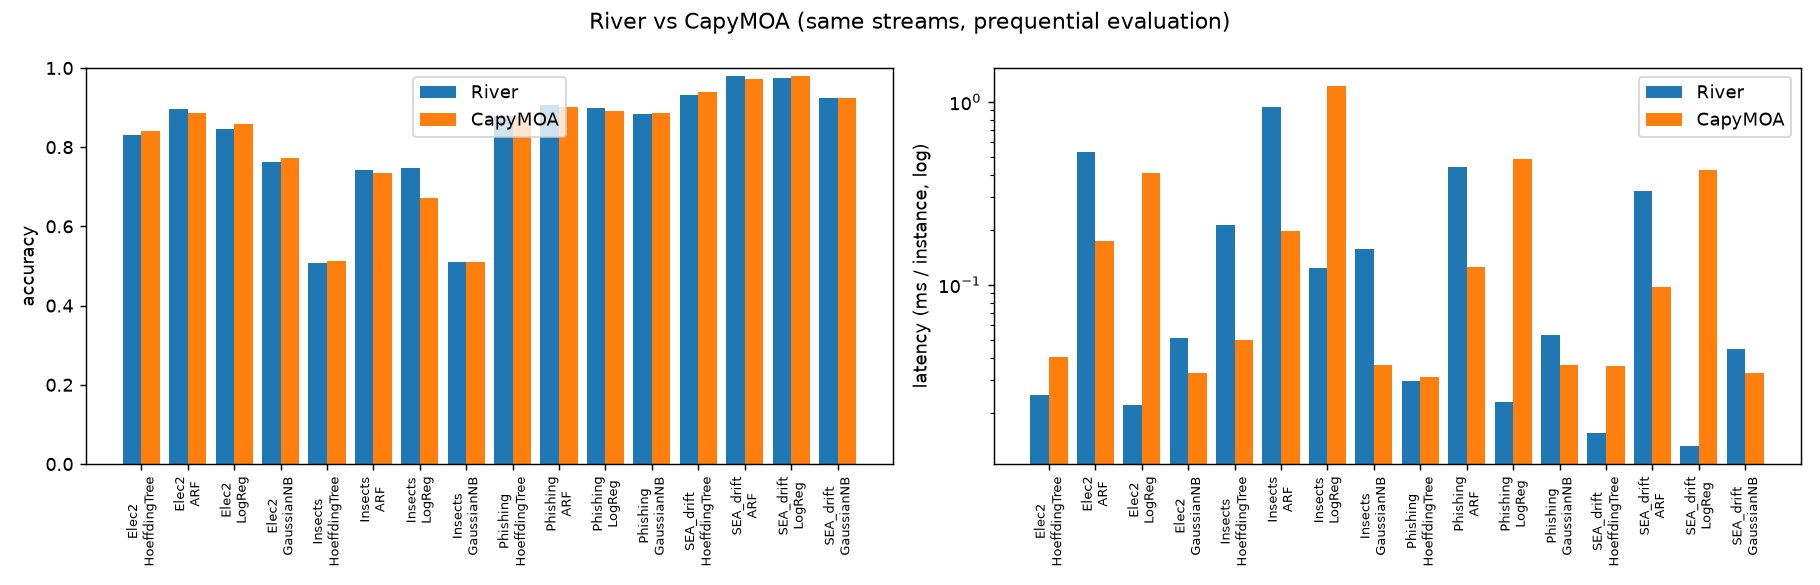

In [8]:
capy_clf = importlib.import_module("03_capymoa_classification")
to_numpy = capy_clf.to_numpy
online_standardize = capy_clf.online_standardize
capymoa_models = capy_clf.capymoa_models
score_predictions = capy_clf.score_predictions
run_capymoa = capy_clf.run_capymoa
compare_with_river = capy_clf.compare_with_river

capy_df = run_capymoa()
merged_df = compare_with_river(capy_df)

print("=== CapyMOA Classification Results ===")
display(capy_df.round(4))
print("=== River vs. CapyMOA Comparison ===")
display(merged_df.round(4))
display(Image(filename=str(FIGURES / "river_vs_capymoa.png")))

**Interpretation (Step 8):**  
Predictive accuracy is nearly identical between River and CapyMOA for `HoeffdingTree`, `ARF`, and `GaussianNB` across all 4 datasets (differences within $0.01\text{--}1.1$ percentage points), confirming that both libraries implement the same underlying incremental learners; the only noticeable accuracy gap is on `Insects` for `LogReg` ($74.72\%$ in River with Adam vs. $67.07\%$ in CapyMOA with constant-step SGD). For computationally intensive tree ensembles (`ARF`), CapyMOA's compiled Java backend is **$3.08\times$ to $4.79\times$ faster** than River across every dataset, and on the 33-feature `Insects` stream it is also **$4.29\times\text{--}4.33\times$ faster** for `HoeffdingTree` and `GaussianNB`. Conversely, `LogReg(SGD)` in CapyMOA is $10\times\text{--}32\times$ slower than River's native `LogReg(Adam)` ($\text{speedup} = 0.03\text{--}0.10\times$) because CapyMOA delegates `SGDClassifier` to scikit-learn's Python `partial_fit` on one sample at a time.

---
### Step 9. Stream Clustering in CapyMOA

**Objective:** Evaluate 3 stream clustering algorithms on evolving unsupervised streams, analyzing cluster quality and how the clusters evolve over time (`src/04_capymoa_clustering.py`).

#### Clustering Setup (`src/04_capymoa_clustering.py`)
* **3 Stream Clustering Methods:**
  1. **`CluStream+kMeans`:** `Clustream_with_kmeans(schema, time_window=1000, max_num_kernels=100, k_option=k)` — maintains 100 micro-clusters and groups them into $k$ macro-clusters via $k$-means.
  2. **`DenStream+DBSCAN`:** `Denstream_with_dbscan(schema, horizon=1000, epsilon=0.1, mu=1, init_points=1000)` — density-based micro-clusters with exponential fading and offline DBSCAN macro-clustering (automatically discovers the number of clusters).
  3. **`ClusTree+kMeans`:** `ClusTree(schema, horizon=1000, max_height=8)` — hierarchical tree of micro-clusters with exponential decay, followed by weighted $k$-means on micro-cluster centers.
* **2 Unsupervised Streams (labels used only for evaluation every 1,000 samples):**
  1. **`Blobs_drift` ($N=20,000$, 2D):** 4 Gaussian clusters moving linearly across $[0,1]^2$; **Cluster 4 appears at instance 10,000** (birth) and **Cluster 0 disappears at instance 15,000** (death).
  2. **`Insects` ($N=20,000$, 33D, $k=6$):** Real sensor stream standardized causally via `online_unit_scale(X)`.
* **Metrics:** Evaluated every 1,000 instances using **Silhouette**, **SSQ** (mean squared distance to closest center), **Adjusted Rand Index (ARI)**, **Purity**, **number of clusters (`n_clusters`)**, and **latency (`latency_ms`)**.

=== Stream Clustering Summary ===

dataset,method,n_samples,mean_n_clusters,mean_silhouette,mean_SSQ,mean_ARI,mean_purity,time_s,latency_ms
Blobs_drift,CluStream+kMeans,20000,3.95,0.6260,0.0183,0.7819,0.8420,4.7536,0.2377
Blobs_drift,DenStream+DBSCAN,20000,4.50,0.8046,0.0049,0.9984,0.9994,3.6758,0.1838
Blobs_drift,ClusTree+kMeans,20000,4.00,0.7859,0.0048,0.9435,0.9520,1.0177,0.0509
Insects,CluStream+kMeans,20000,6.00,0.0956,0.0389,0.2935,0.6217,29.7960,1.4898
Insects,DenStream+DBSCAN,20000,9.45,0.0937,0.0357,0.3447,0.6803,32.9818,1.6491
Insects,ClusTree+kMeans,20000,6.00,0.1329,0.0335,0.2254,0.5710,1.2445,0.0622


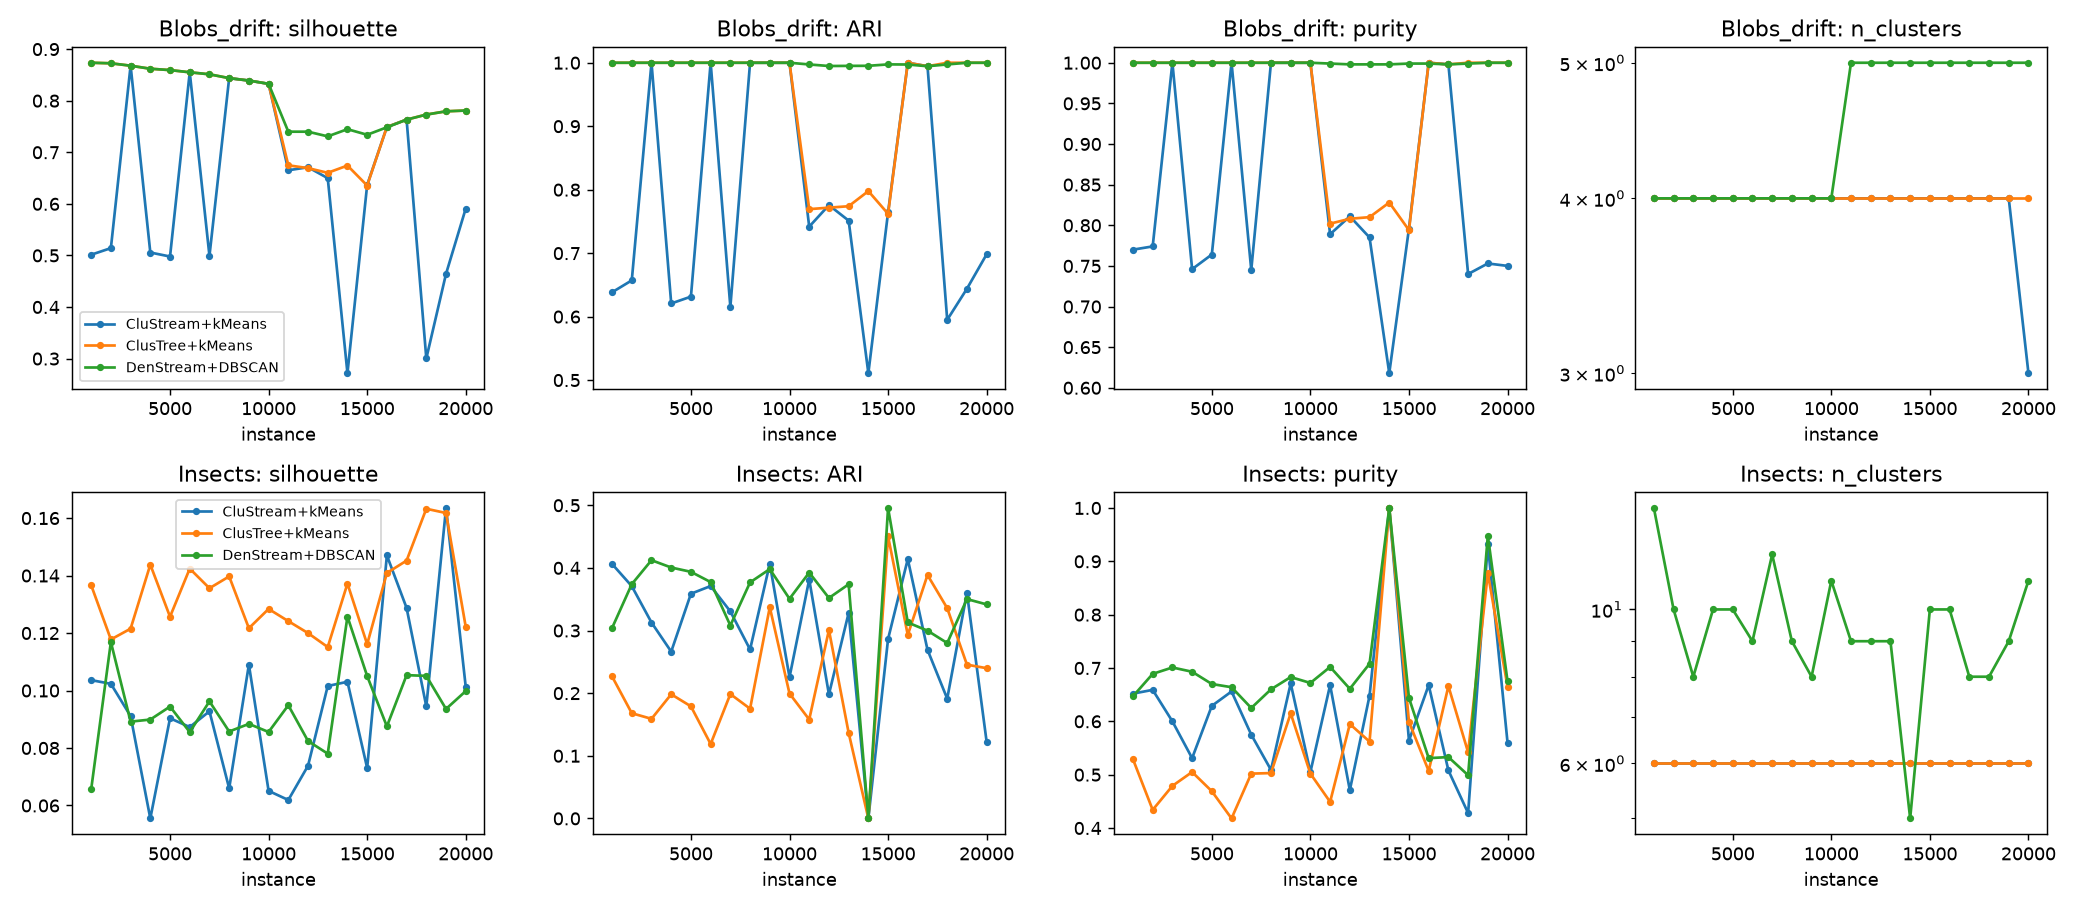

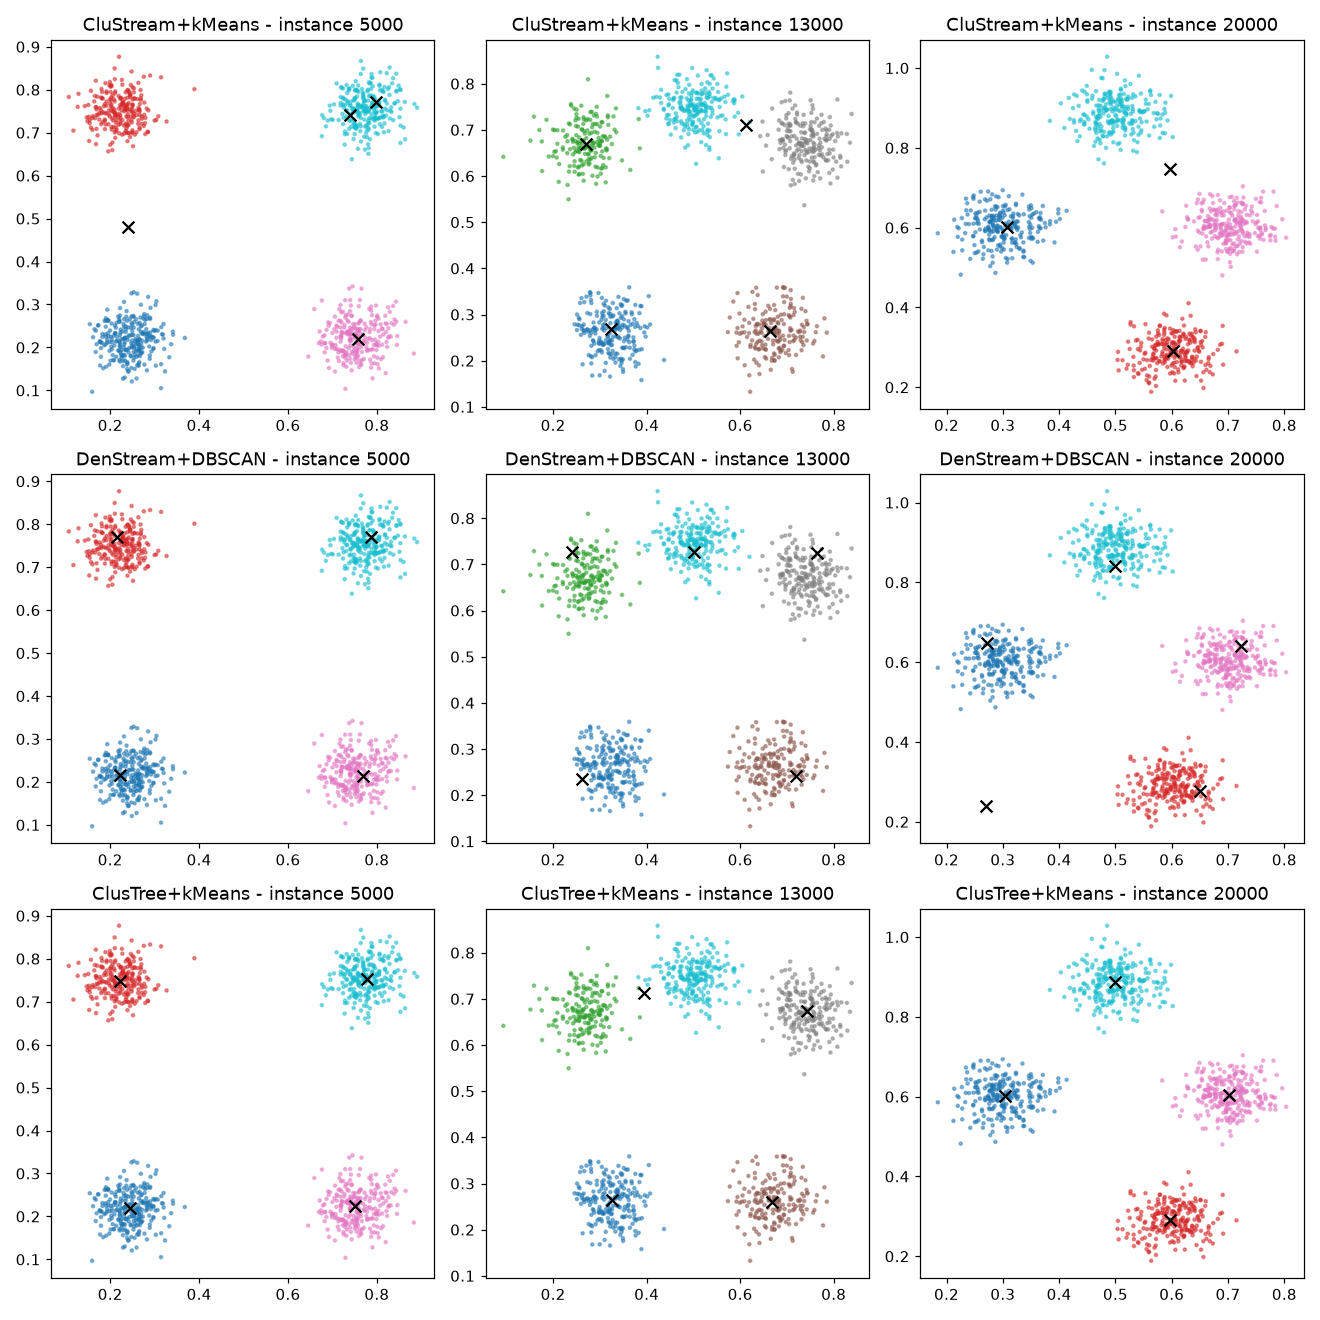

In [9]:
capy_clust = importlib.import_module("04_capymoa_clustering")
DATASETS = capy_clust.DATASETS
EVAL_EVERY = capy_clust.EVAL_EVERY
N_CLUSTERING = capy_clust.N_CLUSTERING
SNAPSHOTS = capy_clust.SNAPSHOTS
blobs_drift_stream = capy_clust.blobs_drift_stream
insects_stream = capy_clust.insects_stream
online_unit_scale = capy_clust.online_unit_scale
clusterers = capy_clust.clusterers
current_centers = capy_clust.current_centers
purity = capy_clust.purity
evaluate_window = capy_clust.evaluate_window
run_clusterer = capy_clust.run_clusterer
plot_over_time = capy_clust.plot_over_time
plot_snapshots = capy_clust.plot_snapshots

summary_rows, time_rows = [], []
for ds, make_stream in DATASETS.items():
    stream, k = make_stream()
    snapshots_by_method = {}
    for method, clusterer in clusterers(stream.get_schema(), k).items():
        records, snapshots, elapsed, n_seen = run_clusterer(stream, clusterer, N_CLUSTERING, k)
        snapshots_by_method[method] = snapshots
        for rec in records:
            time_rows.append({"dataset": ds, "method": method, **rec})
        df_rec = pd.DataFrame(records)
        summary_rows.append({
            "dataset": ds,
            "method": method,
            "n_samples": n_seen,
            **df_rec.drop(columns="instance").mean().add_prefix("mean_").to_dict(),
            "time_s": elapsed,
            "latency_ms": 1000 * elapsed / n_seen,
        })
        print({k_: round(v, 4) if isinstance(v, float) else v for k_, v in summary_rows[-1].items()})
    if ds == "Blobs_drift":
        plot_snapshots(snapshots_by_method)

clust_summary_df = pd.DataFrame(summary_rows)
clust_over_time_df = pd.DataFrame(time_rows)
clust_summary_df.to_csv(TABLES / "capymoa_clustering_summary.csv", index=False)
clust_over_time_df.to_csv(TABLES / "capymoa_clustering_over_time.csv", index=False)
plot_over_time(clust_over_time_df)

print("=== Stream Clustering Summary ===")
display(clust_summary_df.round(4))
display(Image(filename=str(FIGURES / "clustering_over_time.png")))
display(Image(filename=str(FIGURES / "clustering_snapshots_Blobs_drift.png")))

**Interpretation (Step 9):**  
On `Blobs_drift`, `DenStream+DBSCAN` achieves near-perfect clustering ($\text{mean ARI} = 0.9984$, $\text{purity} = 0.9994$, $\text{silhouette} = 0.8046$) because its density-based macro-clustering automatically adjusts the number of clusters (`mean_n_clusters = 4.5`) when Cluster 4 appears at $t=10,000$ (5 active clusters, visible at snapshot 13,000) and Cluster 0 disappears at $t=15,000$ (back to 4 clusters at snapshot 20,000), whereas `CluStream+kMeans` ($\text{ARI} = 0.7819$) and `ClusTree+kMeans` ($\text{ARI} = 0.9435$) are fixed at $k=4$. On the 33-dimensional `Insects` stream, all methods experience lower silhouette ($0.09\text{--}0.13$) and ARI ($0.23\text{--}0.34$) due to high dimensionality and overlapping classes, though `DenStream+DBSCAN` still achieves the highest ARI ($0.3447$) and purity ($0.6803$). In terms of speed, `ClusTree+kMeans` is by far the fastest algorithm ($\sim 0.05\text{--}0.06\text{ ms/instance}$ on both streams, over $25\times$ faster than `CluStream` and `DenStream` on `Insects`) thanks to its hierarchical tree indexing of micro-clusters.

---
### Step 10. Bonus: AutoML in CapyMOA

**Objective:** Explore CapyMOA's `capymoa.automl` module by comparing two online AutoML strategies (`BanditClassifier` with `EpsilonGreedy` and `SuccessiveHalvingClassifier`) against their individual base classifiers on `Elec2` and `SEA_drift` (`src/05_capymoa_automl.py`).

dataset,approach,Accuracy,MacroF1,Kappa,time_s,latency_ms
Elec2,single: HT(gp=50),0.8447,0.8418,0.6837,0.8247,0.0412
Elec2,single: HT(gp=200),0.8419,0.8390,0.6781,0.7274,0.0364
Elec2,single: HAT,0.8793,0.8775,0.7550,0.8180,0.0409
Elec2,single: NaiveBayes,0.7720,0.7620,0.5271,0.6093,0.0305
Elec2,single: ARF(10),0.9049,0.9032,0.8064,3.8238,0.1912
Elec2,AutoML: Bandit (eps-greedy),0.7711,0.7613,0.5256,67.2698,3.3635
Elec2,AutoML: Successive Halving,0.9049,0.9032,0.8064,157.1948,7.8597
SEA_drift,single: HT(gp=50),0.9372,0.9284,0.8569,0.6331,0.0317
SEA_drift,single: HT(gp=200),0.9393,0.9300,0.8600,0.6096,0.0305
SEA_drift,single: HAT,0.9626,0.9567,0.9135,0.7931,0.0397


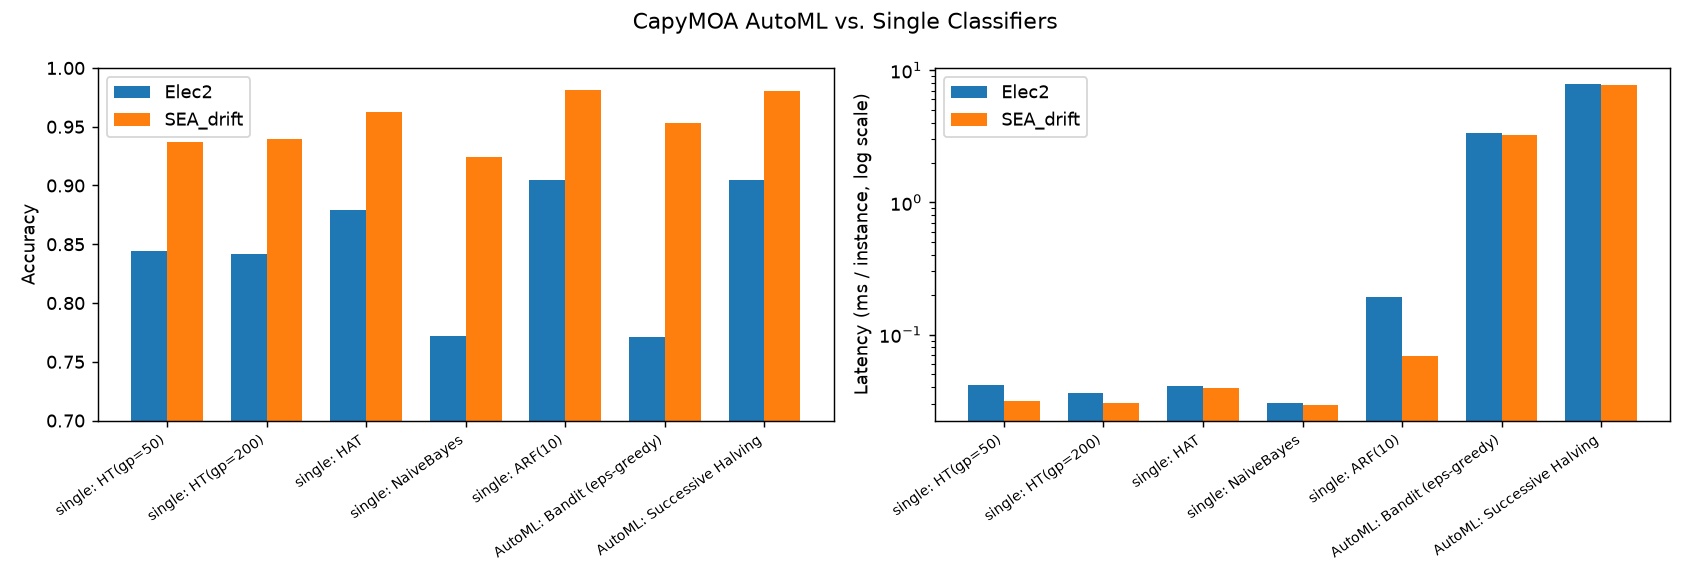

In [10]:
from capymoa.automl import BanditClassifier, EpsilonGreedy, SuccessiveHalvingClassifier
from capymoa.stream import NumpyStream

capy_automl = importlib.import_module("05_capymoa_automl")
AUTOML_DATASETS = capy_automl.AUTOML_DATASETS
candidates = capy_automl.candidates
evaluate = capy_automl.evaluate

automl_rows = []
for ds in AUTOML_DATASETS:
    data = load_classification(ds)
    X, y, names, _ = to_numpy(data)
    stream = NumpyStream(X, y, dataset_name=ds, feature_names=names, target_type="categorical")
    schema, n = stream.get_schema(), len(data)

    for name, model in candidates(schema).items():
        automl_rows.append({"dataset": ds, "approach": f"single: {name}", **evaluate(stream, model, n)})
        print(automl_rows[-1])

    automl_methods = {
        "AutoML: Bandit (eps-greedy)": BanditClassifier(
            schema,
            random_seed=SEED,
            base_classifiers=list(candidates(schema).values()),
            policy=EpsilonGreedy(epsilon=0.1, burn_in=100),
        ),
        "AutoML: Successive Halving": SuccessiveHalvingClassifier(
            schema,
            random_seed=SEED,
            base_classifiers=list(candidates(schema).values()),
            max_instances=n,
        ),
    }
    for name, learner in automl_methods.items():
        automl_rows.append({"dataset": ds, "approach": name, **evaluate(stream, learner, n)})
        print(automl_rows[-1])

automl_df = pd.DataFrame(automl_rows)
automl_df.to_csv(TABLES / "capymoa_automl.csv", index=False)
display(automl_df.round(4))

# Plot Accuracy and Latency comparison across single classifiers and AutoML approaches
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
approaches = automl_df["approach"].unique()
x = np.arange(len(approaches))
for i, ds in enumerate(AUTOML_DATASETS):
    sub = automl_df[automl_df["dataset"] == ds].set_index("approach").loc[approaches]
    offset = -0.18 if i == 0 else 0.18
    axes[0].bar(x + offset, sub["Accuracy"], 0.35, label=ds)
    axes[1].bar(x + offset, sub["latency_ms"], 0.35, label=ds)
for ax in axes:
    ax.set_xticks(x, approaches, rotation=30, ha="right", fontsize=8)
    ax.legend()
axes[0].set_ylim(0.7, 1.0)
axes[0].set_ylabel("Accuracy")
axes[1].set_yscale("log")
axes[1].set_ylabel("Latency (ms / instance, log scale)")
fig.suptitle("CapyMOA AutoML vs. Single Classifiers")
fig.tight_layout()
fig.savefig(FIGURES / "capymoa_automl.png", dpi=130)
plt.close(fig)
display(Image(filename=str(FIGURES / "capymoa_automl.png")))

**Interpretation (Step 10):**  
`AutoML: Successive Halving` reliably identifies and converges to the strongest classifier in the candidate pool (`ARF(10)`), matching its top accuracy on both `Elec2` ($90.49\%$ vs. $90.49\%$) and `SEA_drift` ($98.08\%$ vs. $98.09\%$). In contrast, `AutoML: Bandit (eps-greedy)` reaches $95.36\%$ on `SEA_drift` but drops to $77.11\%$ on `Elec2` (matching the weakest candidate, `NaiveBayes`), because its $\epsilon$-greedy exploration continues selecting inferior arms on temporally correlated streams. Furthermore, online AutoML comes with a steep computational cost: `Bandit` ($3.26\text{--}3.36\text{ ms/instance}$) and `Successive Halving` ($7.66\text{--}7.86\text{ ms/instance}$) are **$17\times$ to $110\times$ slower** than running `ARF(10)` directly ($0.07\text{--}0.19\text{ ms/instance}$) because multiple candidate models must be trained and evaluated in parallel.

---
## Overall Conclusion

1. **Choosing an Online Learner (Accuracy vs. Resource Cost):**
   * **Adaptive Random Forest (`ARF`)** achieves the highest predictive accuracy across most regression and classification streams (`Bikes`, `Taxis`, `Elec2`, `Phishing`, `SEA_drift`), making it the strongest choice when latency ($\sim 0.1\text{--}1.0\text{ ms/instance}$) and memory ($\sim 1\text{--}65\text{ MB}$) are acceptable.
   * **Linear Models with Adaptive Learning Rate (`LinearReg(Adam)` / `LogReg(Adam)`)** offer the best efficiency-to-accuracy trade-off: they process each sample in $0.01\text{--}0.12\text{ ms}$, use less than $11\text{ KB}$ of memory, and even outperform tree ensembles on high-dimensional streams such as `Insects` ($74.72\%$ accuracy).
2. **Handling Concept Drift:**
   * Unadapted incremental trees (`HoeffdingTree`) suffer severe performance degradation under concept drift (`Bikes`, `Elec2`, `Insects`).
   * Monitoring model error with **`ADWIN`** (or **`PageHinkley`** in regression / **`HDDM_A`** in classification) detects drifts with low delay and minimal false alarms, whereas overly sensitive detectors (`KSWIN`, `EDDM`) can degrade performance on noisy streams by triggering excessive resets.
   * **Built-in subtree replacement (`HoeffdingAdaptiveTree` / `HAT`)** provides the smoothest adaptation (`Bikes` $R^2=0.8255$, `SEA_drift` accuracy $=94.67\%$) by replacing only degraded branches rather than resetting the entire model.
3. **River vs. CapyMOA:**
   * **River** excels in pure-Python ergonomics, composable preprocessing pipelines (`StandardScaler | Model`), fast native gradient-based linear models (`Adam`), and custom per-instance drift monitoring loops.
   * **CapyMOA** excels in high-throughput tree and ensemble learning (`ARF` is **$3.1\times\text{--}4.8\times$ faster** than in River with matching accuracy), evolving stream clustering (`DenStream+DBSCAN` for dynamic cluster counts, `ClusTree` for sub-$0.06\text{ ms}$ latency), and out-of-the-box streaming AutoML (`SuccessiveHalvingClassifier`).